# A Comparative Study of Transfer-Learning CNNs for Musculoskeletal X-Ray Classification
**DenseNet121 vs ResNet50 vs EfficientNet-B0 on MURA (internal) and FracAtlas (external)**

How to use this notebook (Windows / VS Code friendly, run cells top to bottom):

1. Put this notebook beside `mura/` and `fracatlas/`, or inside a folder containing `prepared_data/mura/` and `prepared_data/fracatlas/`.
2. Run the notebook top to bottom. Its default reduced-data run samples up to 1,000 MURA training images per class and trains for at most 2 + 4 epochs per model.
3. Validation, MURA test, and FracAtlas data are not downsampled. Review the audit output and `results/metrics/audit_issues.csv` before interpreting results.
4. Accuracy is measured from the held-out data and is not guaranteed to exceed 90%; do not tune against test or external-test results.

Protocol (fixed before any test evaluation):
* Positive class = `abnormal` (MURA) / fractured (FracAtlas). Label 1 = positive.
* Checkpoint selection metric = validation ROC-AUC. Decision threshold chosen on MURA **validation** only and reused unchanged for MURA test and FracAtlas.
* FracAtlas is never used for training, model selection, threshold tuning or hyper-parameter tuning.
* Loss = BCE with inverse-frequency `pos_weight` computed from training labels only. Validation/test sets are never rebalanced.

Nothing in this notebook contains pre-computed results. Every number is produced when you run it.

## 1. Environment

In [2]:
%pip install torchvision scikit-learn pandas numpy matplotlib pillow tqdm

In [3]:
# Uncomment on first run. Install PyTorch first from https://pytorch.org (choose your CUDA version), then:
# %pip install torchvision scikit-learn pandas numpy matplotlib pillow tqdm

REQS = """torch>=2.3
torchvision>=0.18
numpy
pandas
scikit-learn
matplotlib
pillow
tqdm
ipykernel
"""
from pathlib import Path
Path("requirements.txt").write_text(REQS)
print("requirements.txt written")

requirements.txt written


## 2. Imports, settings and reproducibility

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os, io, sys, json, time, copy, random, hashlib, re, platform, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, Markdown
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, confusion_matrix, classification_report)
warnings.filterwarnings("ignore")
Image.MAX_IMAGE_PIXELS = None

# ======================= USER SETTINGS =======================
SMOKE_TEST = False         # False runs the reduced-data experiment, not a smoke test.
RESUME = True              # skip training of a model if its checkpoint + info already exist
ALLOW_CONTINUE_WITH_BLOCKING_ISSUES = True
ROOT = Path.cwd()
# Modified path to target the unzipped prepared_data directory accurately
DATA_ROOT = Path("/content/prepared_data")
# =============================================================

MURA_DIR = DATA_ROOT / "mura"
FRAC_DIR = DATA_ROOT / "fracatlas"
TAG = "_smoke" if SMOKE_TEST else ""
RESULTS = ROOT / f"results{TAG}"
CKPT = ROOT / f"checkpoints{TAG}"
D_METRICS, D_PLOTS = RESULTS / "metrics", RESULTS / "plots"
D_CM, D_CAM, D_MIS = RESULTS / "confusion_matrices", RESULTS / "gradcam", RESULTS / "misclassified"
for d in (D_METRICS, D_PLOTS, D_CM, D_CAM, D_MIS, CKPT):
    d.mkdir(parents=True, exist_ok=True)

ARCHS = ["densenet121", "resnet50", "efficientnet_b0"]
PRETTY = {"densenet121": "DenseNet121", "resnet50": "ResNet50", "efficientnet_b0": "EfficientNet-B0"}

CFG = dict(
    seed=42, img_size=224, batch_size=32,
    num_workers=0 if platform.system() == "Windows" else 2,   # >0 often breaks in notebooks on Windows
    use_amp=True,
    stage1_epochs=2, stage2_epochs=4, early_stop_patience=2,
    weight_decay=1e-4, head_hidden=256, head_dropout=0.3,
    sched_factor=0.5, sched_patience=1,
    selection_metric="val_auc",          # fixed in advance, higher is better
    threshold_mode="val_youden",         # "val_youden" or "fixed_0.5"; chosen on MURA validation only
    n_boot=100, latency_runs=10, gradcam_per_category=1,
    train_samples_per_class=1000,
)
# Architecture-specific learning rates (documented, same tuning budget = none: values are fixed a priori)
ARCH_CFG = {
    "densenet121":     dict(lr_head_s1=1e-3, lr_head_s2=1e-4, lr_backbone_s2=1e-5),
    "resnet50":        dict(lr_head_s1=1e-3, lr_head_s2=1e-4, lr_backbone_s2=1e-5),
    "efficientnet_b0": dict(lr_head_s1=1e-3, lr_head_s2=2e-4, lr_backbone_s2=2e-5),
}
SMOKE_N = dict(train=128, val=64, test=64, external=64)
if SMOKE_TEST:
    CFG.update(stage1_epochs=1, stage2_epochs=1, n_boot=50, latency_runs=10, batch_size=16)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(CFG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(CFG["use_amp"] and device.type == "cuda")
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| device:", device,
      "| AMP:", USE_AMP, "| SMOKE_TEST:", SMOKE_TEST)
print("ROOT:", ROOT, "| DATA_ROOT:", DATA_ROOT)
if device.type == "cpu":
    print("NOTE: CPU detected; reduced training sampling/epochs are enabled.")

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=str))

Python 3.13.16 | torch 2.11.0+cu130 | device: cuda | AMP: True | SMOKE_TEST: False
ROOT: /content | DATA_ROOT: /content/prepared_data


In [6]:
import zipfile
from pathlib import Path

# Source zip file from Google Drive
zip_path = Path('/content/drive/MyDrive/prepared_data/mura.zip')
# Target directory inside the notebook environment
target_dir = Path('/content/prepared_data')
target_dir.mkdir(parents=True, exist_ok=True)

if zip_path.exists():
    print(f"Unzipping {zip_path} to {target_dir}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(target_dir)
    print("Unzipping complete!")
else:
    print(f"Error: The file {zip_path} was not found on your Google Drive.")

Unzipping /content/drive/MyDrive/prepared_data/mura.zip to /content/prepared_data...
Unzipping complete!


## 3. Mandatory dataset audit
This section only **reads** the data. Nothing is moved, deleted or rewritten on disk. Every issue is logged to `audit_issues.csv`.

In [7]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
EXPECTED = {("mura", "train"): 33146, ("mura", "val"): 3662, ("mura", "test"): 3197,
            ("fracatlas", "external_test"): 4083}
ISSUES = []
def log_issue(check, severity, n, detail):
    ISSUES.append(dict(check=check, severity=severity, n=n, detail=detail))
    print(f"[{severity}] {check}: n={n} - {detail}")

def list_images(d):
    d = Path(d)
    if not d.exists():
        return []
    return sorted(p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT)

# ---- 3.1 paths and counts
rows = []
for split in ["train", "val", "test"]:
    for cls in ["normal", "abnormal"]:
        d = MURA_DIR / split / cls
        if not d.exists():
            log_issue("missing_directory", "BLOCKING", 1, str(d))
        for p in list_images(d):
            rows.append(dict(dataset="mura", split=split, label_name=cls, label=int(cls == "abnormal"), path=str(p)))
for cls in ["normal", "abnormal"]:
    d = FRAC_DIR / "external_test" / cls
    if not d.exists():
        log_issue("missing_directory", "BLOCKING", 1, str(d))
    for p in list_images(d):
        rows.append(dict(dataset="fracatlas", split="external_test", label_name=cls, label=int(cls == "abnormal"), path=str(p)))
index = pd.DataFrame(rows)
assert len(index) > 0, "No images found - check ROOT and the prepared_data folder."
index["basename"] = index["path"].map(lambda p: Path(p).name)

counts = index.groupby(["dataset", "split"]).size()
for key, exp in EXPECTED.items():
    got = int(counts.get(key, 0))
    if got != exp:
        log_issue("count_mismatch", "WARNING", got - exp, f"{key}: found {got}, reported {exp}")
    else:
        print(f"OK count {key}: {got}")

# ---- 3.2 manifests and their real column names
MANIFESTS = {}
for ds, base in [("mura", MURA_DIR), ("fracatlas", FRAC_DIR)]:
    for f in (sorted(base.rglob("*.csv")) if base.exists() else []):
        try:
            mdf = pd.read_csv(f)
        except Exception as e:
            log_issue("manifest_unreadable", "WARNING", 1, f"{f}: {e!r}"); continue
        MANIFESTS[(ds, f.name)] = mdf
        print(f"\nManifest [{ds}] {f.relative_to(ROOT) if ROOT in f.parents else f}  shape={mdf.shape}")
        print("columns:", list(mdf.columns))
        display(mdf.head(3))
if not MANIFESTS:
    log_issue("no_manifest_found", "WARNING", 0, "No CSV manifests found; patient-level checks will be limited.")

[WARNING] count_mismatch: n=-2020 - ('mura', 'train'): found 31126, reported 33146
[WARNING] count_mismatch: n=-250 - ('mura', 'val'): found 3412, reported 3662
[WARNING] count_mismatch: n=-419 - ('mura', 'test'): found 2778, reported 3197
OK count ('fracatlas', 'external_test'): 4083

Manifest [mura] prepared_data/mura/manifest.csv  shape=(40009, 6)
columns: ['dataset', 'split', 'image', 'label', 'source', 'patient']


,dataset,split,image,label,source,patient
0,MURA,train,C:\Users\sukha\Downloads\FracAtlas\FracAtlas\p...,normal,C:\Users\sukha\.cache\kagglehub\datasets\cjinn...,train/patient08902
1,MURA,train,C:\Users\sukha\Downloads\FracAtlas\FracAtlas\p...,normal,C:\Users\sukha\.cache\kagglehub\datasets\cjinn...,train/patient08902
2,MURA,train,C:\Users\sukha\Downloads\FracAtlas\FracAtlas\p...,normal,C:\Users\sukha\.cache\kagglehub\datasets\cjinn...,train/patient08902



Manifest [fracatlas] prepared_data/fracatlas/manifest.csv  shape=(4083, 4)
columns: ['image', 'label', 'source_label', 'image_id']


,image,label,source_label,image_id
0,C:\Users\sukha\Downloads\FracAtlas\FracAtlas\p...,normal,Non_fractured,IMG0000000.jpg
1,C:\Users\sukha\Downloads\FracAtlas\FracAtlas\p...,normal,Non_fractured,IMG0000001.jpg
2,C:\Users\sukha\Downloads\FracAtlas\FracAtlas\p...,normal,Non_fractured,IMG0000002.jpg


In [8]:
# ---- 3.3 per-image scan: readability, format, size, channels, hashes (md5 + difference-hash)
def dhash_hex(g, hs=8):
    a = np.asarray(g.resize((hs + 1, hs), Image.BILINEAR), dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten()).tobytes().hex()

def scan_image(p):
    r = dict(path=p, readable=True, error="", md5="", dhash="", width=0, height=0, mode="", fmt="", mean_intensity=np.nan)
    try:
        data = Path(p).read_bytes()
        r["md5"] = hashlib.md5(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            r["fmt"], r["mode"] = im.format, im.mode
            r["width"], r["height"] = im.size
            im.load()
            g = im.convert("L")
            r["dhash"] = dhash_hex(g)
            r["mean_intensity"] = float(np.asarray(g).mean())
    except Exception as e:
        r["readable"], r["error"] = False, repr(e)
    return r

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    scans = list(tqdm(ex.map(scan_image, index["path"].tolist()), total=len(index), desc="Scanning images"))
audit = index.merge(pd.DataFrame(scans), on="path")
print(f"scan finished in {time.time()-t0:.0f}s")

bad = audit[~audit.readable]
if len(bad):
    log_issue("unreadable_images", "WARNING", len(bad), "excluded in memory only (files untouched); see audit_images.csv")
print("\nFormats:\n", audit.groupby(["dataset", "fmt"]).size().to_string())
print("\nColour modes:\n", audit.groupby(["dataset", "mode"]).size().to_string())
print("\nImage size summary (px):")
display(audit[audit.readable].groupby("dataset")[["width", "height"]].describe().T)

Scanning images:   0%|          | 0/41399 [00:00<?, ?it/s]

scan finished in 135s
[WARNING] unreadable_images: n=63 - excluded in memory only (files untouched); see audit_images.csv

Formats:
 dataset    fmt 
fracatlas  JPEG     4083
mura                   4
           PNG     37312

Colour modes:
 dataset    mode
fracatlas  L         605
           RGB      3478
mura                   4
           L       22441
           RGB     14871

Image size summary (px):


dataset         fracatlas          mura
width  count  4024.000000  37312.000000
       mean    561.884443    399.087345
       std     542.860962     91.990350
       min     181.000000     89.000000
       25%     373.000000    362.000000
       50%     373.000000    406.000000
       75%     454.000000    486.000000
       max    2880.000000    512.000000
height count  4024.000000  37312.000000
       mean    637.032058    490.791810
       std     669.783872     47.325337
       min     214.000000    132.000000
       25%     373.000000    512.000000
       50%     454.000000    512.000000
       75%     454.000000    512.000000
       max    2880.000000    512.000000

In [9]:
# ---- 3.4 link manifests to images -> patient id, body part, original split (when the manifest allows it)
def parse_meta(text):
    t = text.replace("\\", "/")
    pat = re.search(r"patient(\d+)", t, re.I)
    body = re.search(r"XR_([A-Z]+)", t, re.I)
    orig = re.search(r"(?:MURA-v1\.1/|/|^)(train|valid)/XR_", t, re.I)
    return (pat.group(1) if pat else None, body.group(1).upper() if body else None,
            orig.group(1).lower() if orig else None)

meta_text, link_info = {}, {}
for ds in ["mura", "fracatlas"]:
    names = set(audit.loc[audit.dataset == ds, "basename"])
    best = (None, None, 0.0)
    for (d2, fname), mdf in MANIFESTS.items():
        if d2 != ds:
            continue
        for col in mdf.columns:
            if mdf[col].dtype != object:
                continue
            key = mdf[col].astype(str).str.replace("\\", "/", regex=False).str.split("/").str[-1]
            cov = key.isin(names).mean()
            if cov > best[2]:
                best = (fname, col, cov)
    link_info[ds] = best
    print(f"{ds}: manifest link -> file={best[0]}, column={best[1]}, coverage={best[2]:.1%}")
    if best[2] > 0.5:
        mdf = MANIFESTS[(ds, best[0])]
        key = mdf[best[1]].astype(str).str.replace("\\", "/", regex=False).str.split("/").str[-1]
        objc = [c for c in mdf.columns if mdf[c].dtype == object]
        txt = mdf[objc].astype(str).agg(" ".join, axis=1)
        for k, t in zip(key, txt):
            meta_text.setdefault((ds, k), t)
    else:
        log_issue("manifest_not_linked", "WARNING", 0, f"{ds}: no manifest column matches image filenames (>50%).")

def row_meta(r):
    own = Path(r["path"]).name   # file name may itself encode patient / study
    txt = own + " " + meta_text.get((r["dataset"], r["basename"]), "")
    return parse_meta(txt)

m = audit.apply(row_meta, axis=1, result_type="expand")
audit["patient_no"], audit["body_part"], audit["orig_split"] = m[0], m[1], m[2]
audit["patient_key"] = np.where(audit.patient_no.notna() & (audit.dataset == "mura"),
                                audit.orig_split.fillna("?") + "|" + audit.body_part.fillna("?") + "|" + audit.patient_no.fillna(""),
                                None)
have_pid = audit.loc[audit.dataset == "mura", "patient_key"].notna().mean()
print(f"\nMURA images with a recoverable patient id: {have_pid:.1%}")
if have_pid < 0.99:
    log_issue("patient_id_unavailable", "WARNING", int((1-have_pid)*100),
              "Patient ids not fully recoverable from manifests/paths: patient-level overlap cannot be fully verified; "
              "bootstrap will fall back to image-level resampling.")

mura: manifest link -> file=manifest.csv, column=image, coverage=100.0%
fracatlas: manifest link -> file=manifest.csv, column=image, coverage=100.0%

MURA images with a recoverable patient id: 100.0%


In [10]:
# ---- 3.5 class counts, duplicates, leakage, label consistency, oversampling, provenance
ok = audit[audit.readable].copy()

cc = ok.groupby(["dataset", "split", "label_name"]).size().rename("n").reset_index()
cc["pct_of_split"] = (100 * cc["n"] / cc.groupby(["dataset", "split"])["n"].transform("sum")).round(2)
display(cc); cc.to_csv(D_METRICS / "audit_class_counts.csv", index=False)

# exact duplicates (md5) and near-duplicates (identical difference hash)
dup_md5 = ok[ok.duplicated("md5", keep=False)].sort_values("md5")
dup_dh = ok[ok.duplicated("dhash", keep=False) & ~ok.duplicated("md5", keep=False)].sort_values("dhash")
pd.concat([dup_md5.assign(kind="exact_md5"), dup_dh.assign(kind="near_dhash")]).to_csv(D_METRICS / "audit_duplicates.csv", index=False)
print(f"exact-duplicate files: {len(dup_md5)} | near-duplicate (dHash-identical, not byte-identical): {len(dup_dh)}")

def multi(g, col):
    return g.groupby("md5")[col].nunique().gt(1).sum()

mu = ok[ok.dataset == "mura"]
n_leak = multi(mu, "split")
if n_leak:
    log_issue("exact_duplicates_across_mura_splits", "BLOCKING", int(n_leak), "same bytes appear in more than one split (leakage)")
lk = ok.groupby("md5")["dataset"].nunique().gt(1).sum()
if lk:
    log_issue("exact_duplicates_mura_vs_fracatlas", "BLOCKING", int(lk), "FracAtlas images also present in MURA")
n_inc = ok.groupby("md5")["label"].nunique().gt(1).sum()
if n_inc:
    log_issue("inconsistent_labels_same_image", "BLOCKING", int(n_inc), "identical bytes carry different labels")
nd_dh = mu.groupby("dhash")["split"].nunique().gt(1).sum()
if nd_dh:
    log_issue("near_duplicates_across_mura_splits", "WARNING", int(nd_dh), "identical dHash across splits (inspect manually; may be false positives)")

# oversampling check inside training directory
tr = mu[mu.split == "train"]
dup_share = tr.duplicated("md5", keep="first").mean()
susp = tr.basename.str.contains(r"(?:copy|dup|aug|oversamp|_\d+_\d+\.)", case=False, regex=True).mean()
print(f"train: duplicate share={dup_share:.2%}, suspicious-filename share={susp:.2%}")
if dup_share > 0.01:
    log_issue("probable_oversampling_in_train", "WARNING", int(tr.duplicated('md5').sum()),
              "training folder contains exact copies; class weights below are computed on the labels actually seen (avoids double balancing)")

# duplicate file names (informational)
dn = ok.groupby("dataset")["basename"].apply(lambda s: int(s.duplicated().sum()))
print("duplicate file names per dataset:", dn.to_dict())
if dn.sum():
    log_issue("duplicate_filenames", "INFO", int(dn.sum()), "same basename in different folders (paths are used as unique ids)")

# manifest label vs folder label
POS = {"abnormal", "1", "1.0", "positive", "fractured"}
NEG = {"normal", "0", "0.0", "negative", "non_fractured", "non-fractured", "nonfractured", "non fractured"}
for ds in ["mura", "fracatlas"]:
    fname, col, cov = link_info[ds]
    if fname is None or cov < 0.5:
        continue
    mdf = MANIFESTS[(ds, fname)]
    key = mdf[col].astype(str).str.replace("\\", "/", regex=False).str.split("/").str[-1]
    for c in mdf.columns:
        vals = set(mdf[c].astype(str).str.lower().unique())
        if c != col and 1 < len(vals) <= 4 and vals <= (POS | NEG):
            lab = mdf[c].astype(str).str.lower().isin(POS).astype(int)
            mm = pd.DataFrame({"basename": key, "mlabel": lab}).drop_duplicates("basename")
            j = ok[ok.dataset == ds].merge(mm, on="basename")
            bad_n = int((j.label != j.mlabel).sum())
            print(f"{ds}: manifest column '{c}' vs folder label -> {bad_n} mismatches of {len(j)}")
            if bad_n:
                log_issue("manifest_label_mismatch", "BLOCKING", bad_n, f"{ds}/{c} disagrees with folder label")

# patient-level overlap train vs val (both come from the official MURA training set)
pk = mu.dropna(subset=["patient_key"])
if len(pk):
    ptr, pva, pte = (set(pk[pk.split == s].patient_key) for s in ["train", "val", "test"])
    ov = ptr & pva
    print(f"patients: train={len(ptr)}, val={len(pva)}, test={len(pte)} | train-val overlap={len(ov)}")
    if ov:
        log_issue("patient_overlap_train_val", "BLOCKING", len(ov), "same patient in train and val -> optimistic validation")
    if ptr & pte:
        log_issue("patient_key_overlap_train_test", "WARNING", len(ptr & pte),
                  "keys include the original split, so overlap here means a real clash")
    print("\nOriginal MURA split by prepared split (provenance):")
    display(pd.crosstab(mu.split, mu.orig_split.fillna("unknown")))
else:
    log_issue("patient_overlap_unverified", "WARNING", 0, "cannot check patient overlap without ids")

# provenance of the internal test split
tot_trval = int(((mu.split == "train") | (mu.split == "val")).sum()); tot_test = int((mu.split == "test").sum())
print(f"\nProvenance: train+val={tot_trval}, test={tot_test}. The official MURA release has 36,808 training and "
      f"3,197 validation images, so train+val = original training set and test = original validation set is consistent "
      f"with these counts (confirm with the crosstab above when original paths are in the manifest).")

# save
audit.to_csv(D_METRICS / "audit_images.csv", index=False)
issues_df = pd.DataFrame(ISSUES, columns=["check", "severity", "n", "detail"])
issues_df.to_csv(D_METRICS / "audit_issues.csv", index=False)

summary = ["# Dataset audit summary", "", f"Images scanned: {len(audit)}; unreadable: {int((~audit.readable).sum())}", "",
           "## Class counts", cc.to_string(index=False), "", "## Issues",
           issues_df.to_string(index=False) if len(issues_df) else "No issues detected."]
(D_METRICS / "audit_summary.md").write_text("\n".join(summary))

blocking = [i for i in ISSUES if i["severity"] == "BLOCKING"]
if blocking and not ALLOW_CONTINUE_WITH_BLOCKING_ISSUES:
    raise RuntimeError(f"{len(blocking)} BLOCKING dataset issue(s) found (see above / audit_issues.csv). Review them, decide on a "
                       "correction, then set ALLOW_CONTINUE_WITH_BLOCKING_ISSUES=True only if you accept them.")
print("\nAudit finished.", len(ISSUES), "issue(s) logged.")

,dataset,split,label_name,n,pct_of_split
0,fracatlas,external_test,abnormal,719,17.87
1,fracatlas,external_test,normal,3305,82.13
2,mura,test,abnormal,1364,49.10
3,mura,test,normal,1414,50.90
4,mura,train,abnormal,12758,40.99
5,mura,train,normal,18364,59.01
6,mura,val,abnormal,1401,41.06
7,mura,val,normal,2011,58.94


exact-duplicate files: 33 | near-duplicate (dHash-identical, not byte-identical): 2689
[BLOCKING] exact_duplicates_across_mura_splits: n=1 - same bytes appear in more than one split (leakage)
[WARNING] near_duplicates_across_mura_splits: n=232 - identical dHash across splits (inspect manually; may be false positives)
train: duplicate share=0.01%, suspicious-filename share=0.00%
duplicate file names per dataset: {'fracatlas': 0, 'mura': 37301}
[INFO] duplicate_filenames: n=37301 - same basename in different folders (paths are used as unique ids)
mura: manifest column 'label' vs folder label -> 15523 mismatches of 37312
[BLOCKING] manifest_label_mismatch: n=15523 - mura/label disagrees with folder label
fracatlas: manifest column 'label' vs folder label -> 0 mismatches of 4024
fracatlas: manifest column 'source_label' vs folder label -> 0 mismatches of 4024
patients: train=6, val=6, test=6 | train-val overlap=6
[BLOCKING] patient_overlap_train_val: n=6 - same patient in train and val -> 

orig_split,train
split,
test,2778
train,31122
val,3412



Provenance: train+val=34534, test=2778. The official MURA release has 36,808 training and 3,197 validation images, so train+val = original training set and test = original validation set is consistent with these counts (confirm with the crosstab above when original paths are in the manifest).

Audit finished. 10 issue(s) logged.


In [11]:
# ---- 3.6 final in-memory splits (unreadable images removed from memory only; disk is untouched)
ok = audit[audit.readable].reset_index(drop=True)
def stratified_subset(df, n, seed=CFG["seed"]):
    if n is None or len(df) <= n:
        return df.reset_index(drop=True)
    parts = [g.sample(min(len(g), max(1, n // 2)), random_state=seed) for _, g in df.groupby("label")]
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)

train_df = ok[(ok.dataset == "mura") & (ok.split == "train")].reset_index(drop=True)
train_size_before_sampling = len(train_df)
train_df = pd.concat([
    group.sample(min(len(group), CFG["train_samples_per_class"]), random_state=CFG["seed"])
    for _, group in train_df.groupby("label")
], ignore_index=True).sample(frac=1, random_state=CFG["seed"]).reset_index(drop=True)
print(f"Training sample: {len(train_df):,}/{train_size_before_sampling:,} images "
      f"({CFG['train_samples_per_class']:,} max per class); validation/test remain unsampled.")
val_df   = ok[(ok.dataset == "mura") & (ok.split == "val")].reset_index(drop=True)
test_df  = ok[(ok.dataset == "mura") & (ok.split == "test")].reset_index(drop=True)
ext_df   = ok[(ok.dataset == "fracatlas")].reset_index(drop=True)
if SMOKE_TEST:
    print("SMOKE TEST: using small stratified subsets (never do this for the real run).")
    train_df, val_df = stratified_subset(train_df, SMOKE_N["train"]), stratified_subset(val_df, SMOKE_N["val"])
    test_df, ext_df = stratified_subset(test_df, SMOKE_N["test"]), stratified_subset(ext_df, SMOKE_N["external"])

for n_, d_ in [("train", train_df), ("val", val_df), ("MURA test", test_df), ("FracAtlas", ext_df)]:
    print(f"{n_:10s} n={len(d_):6d}  abnormal={d_.label.mean():.1%}")

# class weight from verified TRAINING labels only: pos_weight = n_negative / n_positive
n_pos, n_neg = int(train_df.label.sum()), int((1 - train_df.label).sum())
POS_WEIGHT = n_neg / max(n_pos, 1)
print(f"\nTraining labels: normal={n_neg}, abnormal={n_pos} -> pos_weight={POS_WEIGHT:.3f} (inverse-frequency weighted BCE)")

Training sample: 2,000/31,122 images (1,000 max per class); validation/test remain unsampled.
train      n=  2000  abnormal=50.0%
val        n=  3412  abnormal=41.1%
MURA test  n=  2778  abnormal=49.1%
FracAtlas  n=  4024  abnormal=17.9%

Training labels: normal=1000, abnormal=1000 -> pos_weight=1.000 (inverse-frequency weighted BCE)


## 4. Preprocessing
Common pipeline for all three models: grayscale → 3 channels, **aspect-preserving resize + zero padding** to 224×224, ImageNet normalisation.
Training-only augmentation: rotation ≤ 10°, translation ≤ 5 %, scale 0.95–1.05, brightness/contrast ±20 %. No flips (laterality / marker side must not change) and no cropping that could remove anatomy.

Differences between the pretrained torchvision implementations are printed below. The native evaluation transforms differ in resize/crop size and interpolation; here we deliberately use one shared 224×224 letterbox for a controlled comparison.

In [12]:
WEIGHTS = {"densenet121": models.DenseNet121_Weights.IMAGENET1K_V1,
           "resnet50": models.ResNet50_Weights.IMAGENET1K_V1,
           "efficientnet_b0": models.EfficientNet_B0_Weights.IMAGENET1K_V1}
rows_ = []
for k, w in WEIGHTS.items():
    t = w.transforms()
    rows_.append(dict(model=PRETTY[k], weights=w.name, native_resize=t.resize_size[0], native_crop=t.crop_size[0],
                      interpolation=str(t.interpolation).split(".")[-1], mean=tuple(t.mean), std=tuple(t.std)))
prep_table = pd.DataFrame(rows_); display(prep_table)
prep_table.to_csv(D_METRICS / "preprocessing_differences.csv", index=False)

class Letterbox:
    def __init__(self, size, fill=0): self.size, self.fill = size, fill
    def __call__(self, img):
        img = img.convert("RGB")                      # grayscale -> 3 channels
        w, h = img.size; s = self.size / max(w, h)
        nw, nh = max(1, round(w * s)), max(1, round(h * s))
        img = img.resize((nw, nh), Image.BICUBIC)
        canvas = Image.new("RGB", (self.size, self.size), (self.fill,) * 3)
        canvas.paste(img, ((self.size - nw) // 2, (self.size - nh) // 2))
        return canvas

def get_tf(name, train):
    t = WEIGHTS[name].transforms()
    norm = transforms.Normalize(mean=t.mean, std=t.std)
    S = CFG["img_size"]
    if train:
        return transforms.Compose([Letterbox(S),
            transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05), fill=0),
            transforms.ColorJitter(brightness=0.2, contrast=0.2),
            transforms.ToTensor(), norm])
    return transforms.Compose([Letterbox(S), transforms.ToTensor(), norm])

class XrayDataset(Dataset):
    def __init__(self, df, tf): self.paths, self.labels, self.tf = df.path.tolist(), df.label.values.astype("float32"), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            im.load(); x = self.tf(im)
        return x, torch.tensor(self.labels[i]), i

def make_loader(df, name, train):
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    nw = CFG["num_workers"]
    return DataLoader(XrayDataset(df, get_tf(name, train)), batch_size=CFG["batch_size"], shuffle=train,
                      num_workers=nw, pin_memory=(device.type == "cuda"), generator=g,
                      persistent_workers=(nw > 0))

,model,weights,native_resize,native_crop,interpolation,mean,std
0,DenseNet121,IMAGENET1K_V1,256,224,BILINEAR,"(0.485, 0.456, 0.406)","(0.229, 0.224, 0.225)"
1,ResNet50,IMAGENET1K_V1,256,224,BILINEAR,"(0.485, 0.456, 0.406)","(0.229, 0.224, 0.225)"
2,EfficientNet-B0,IMAGENET1K_V1,256,224,BICUBIC,"(0.485, 0.456, 0.406)","(0.229, 0.224, 0.225)"


## 5. Models and two-stage transfer learning
Identical head for all backbones: `Dropout(0.3) → Linear(in,256) → ReLU → Dropout(0.3) → Linear(256,1)` (one logit; sigmoid = P(abnormal)).

| Model | Stage-2 unfrozen part |
|---|---|
| DenseNet121 | `denseblock4` + `norm5` |
| ResNet50 | `layer4` |
| EfficientNet-B0 | last two feature stages (`features[7]`, `features[8]`) |

Stage 1: backbone frozen (BatchNorm kept in eval mode), train head. Stage 2: unfreeze the part above with a lower backbone learning rate, continue with the same data.

In [13]:
def make_head(in_f):
    return nn.Sequential(nn.Dropout(CFG["head_dropout"]), nn.Linear(in_f, CFG["head_hidden"]), nn.ReLU(),
                         nn.Dropout(CFG["head_dropout"]), nn.Linear(CFG["head_hidden"], 1))

def build_model(name, pretrained=True):
    w = WEIGHTS[name] if pretrained else None
    if name == "densenet121":
        m = models.densenet121(weights=w); m.classifier = make_head(m.classifier.in_features)
    elif name == "resnet50":
        m = models.resnet50(weights=w); m.fc = make_head(m.fc.in_features)
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=w); m.classifier = make_head(m.classifier[1].in_features)
    else:
        raise ValueError(name)
    return m

def get_head(m, name):  return m.fc if name == "resnet50" else m.classifier

def get_unfreeze(m, name):
    if name == "densenet121":
        return [m.features.denseblock4, m.features.norm5]
    elif name == "resnet50":
        return [m.layer4]
    elif name == "efficientnet_b0":
        return [m.features[7], m.features[8]]
    else:
        raise ValueError(name)

def set_stage(m, name, stage):
    for p in m.parameters(): p.requires_grad = False
    for p in get_head(m, name).parameters(): p.requires_grad = True
    if stage == 2:
        for mod in get_unfreeze(m, name):
            for p in mod.parameters(): p.requires_grad = True

def count_params(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)

def freeze_bn_if_frozen(m):
    for mod in m.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in mod.parameters()):
            mod.eval()

# quick shape check
for n_ in ARCHS:
    mm = build_model(n_, pretrained=False).eval()
    with torch.no_grad(): o = mm(torch.zeros(2, 3, CFG["img_size"], CFG["img_size"]))
    tot, _ = count_params(mm); print(f"{PRETTY[n_]:16s} output {tuple(o.shape)}  params={tot/1e6:.2f}M")

DenseNet121      output (2, 1)  params=7.22M
ResNet50         output (2, 1)  params=24.03M
EfficientNet-B0  output (2, 1)  params=4.34M


## 6. Training (Stage 1 → Stage 2, early stopping, LR scheduling, best-checkpoint saving)

In [14]:
def epoch_metrics(P, Y, loss):
    P, Y = np.asarray(P), np.asarray(Y)
    pred = (P >= 0.5).astype(int)
    tp = ((pred == 1) & (Y == 1)).sum(); fp = ((pred == 1) & (Y == 0)).sum(); fn = ((pred == 0) & (Y == 1)).sum()
    f1 = 2 * tp / max(2 * tp + fp + fn, 1)
    auc = roc_auc_score(Y, P) if len(np.unique(Y)) == 2 else float("nan")
    return dict(loss=loss, acc=float((pred == Y).mean()), auc=float(auc), f1=float(f1))

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    if train: freeze_bn_if_frozen(model)
    tot, n, P, Y = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y, _ in loader:
            x, y = x.to(device, non_blocking=True), y.to(device)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                logit = model(x).squeeze(1)
            loss = criterion(logit.float(), y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            tot += loss.item() * len(y); n += len(y)
            P.append(torch.sigmoid(logit.float()).detach().cpu().numpy()); Y.append(y.cpu().numpy())
    return epoch_metrics(np.concatenate(P), np.concatenate(Y), tot / n)

def train_model(name):
    ckpt, info_p, hist_p = CKPT / f"{name}_best.pt", D_METRICS / f"{name}_train_info.json", D_METRICS / f"{name}_history.csv"
    if RESUME and ckpt.exists() and info_p.exists() and hist_p.exists():
        print(f"[{name}] checkpoint found - skipping training (RESUME=True)"); return json.loads(info_p.read_text())
    seed_everything(CFG["seed"])
    a = ARCH_CFG[name]
    model = build_model(name).to(device)
    tl, vl = make_loader(train_df, name, True), make_loader(val_df, name, False)
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, device=device))
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
    hist, best, best_info, t_train = [], -float("inf"), {}, 0.0
    for stage, n_ep in [(1, CFG["stage1_epochs"]), (2, CFG["stage2_epochs"])]:
        if stage == 2 and ckpt.exists():                      # start fine-tuning from the best stage-1 weights
            model.load_state_dict(torch.load(ckpt, map_location=device)["model"])
        set_stage(model, name, stage)
        head_ids = {id(p) for p in get_head(model, name).parameters()}
        head_p = [p for p in model.parameters() if p.requires_grad and id(p) in head_ids]
        back_p = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
        groups = [dict(params=head_p, lr=a["lr_head_s1"] if stage == 1 else a["lr_head_s2"])]
        if back_p: groups.append(dict(params=back_p, lr=a["lr_backbone_s2"]))
        opt = torch.optim.AdamW(groups, weight_decay=CFG["weight_decay"])
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=CFG["sched_factor"], patience=CFG["sched_patience"])
        tot, trn = count_params(model); bad = 0
        print(f"\n[{PRETTY[name]}] stage {stage}: trainable {trn:,} / {tot:,} params")
        for ep in range(1, n_ep + 1):
            t0 = time.time()
            tr = run_epoch(model, tl, crit, opt, scaler)
            va = run_epoch(model, vl, crit)
            sched.step(va["loss"]); dt = time.time() - t0; t_train += dt
            hist.append(dict(model=name, stage=stage, epoch=ep, lr_head=opt.param_groups[0]["lr"], epoch_sec=dt,
                             train_loss=tr["loss"], train_acc=tr["acc"], train_auc=tr["auc"],
                             val_loss=va["loss"], val_acc=va["acc"], val_auc=va["auc"], val_f1=va["f1"]))
            score = va["auc"] if CFG["selection_metric"] == "val_auc" else -va["loss"]
            flag = ""
            if score > best:
                best, bad = score, 0; flag = "  <- best"
                best_info = dict(stage=stage, epoch=ep, val_auc=va["auc"], val_loss=va["loss"])
                torch.save(dict(model=model.state_dict(), info=best_info, cfg=CFG), ckpt)
            else:
                bad += 1
            print(f"  s{stage} ep{ep:02d} {dt:5.0f}s | train loss {tr['loss']:.4f} acc {tr['acc']:.3f} | "
                  f"val loss {va['loss']:.4f} acc {va['acc']:.3f} auc {va['auc']:.4f}{flag}")
            if bad >= CFG["early_stop_patience"]:
                print("  early stopping"); break
    pd.DataFrame(hist).to_csv(hist_p, index=False)
    tot, trn2 = count_params(model)
    info = dict(model=name, total_params=tot, trainable_params_stage2=trn2, train_seconds=t_train,
                best=best_info, arch_cfg=a, pos_weight=POS_WEIGHT, selection_metric=CFG["selection_metric"],
                epochs_run=len(hist), cfg={k: v for k, v in CFG.items()})
    save_json(info, info_p); save_json(dict(CFG=CFG, ARCH_CFG=ARCH_CFG), D_METRICS / "experiment_config.json")
    return info

TRAIN_INFO = {}

### 6.1 Smoke test of the whole mechanism (data loading, shapes, loss, checkpoint round-trip)

In [15]:
name = "resnet50"
xb, yb, _ = next(iter(make_loader(train_df, name, True)))
print("batch", tuple(xb.shape), xb.dtype, "| labels", yb[:8].tolist(), "| min/max", float(xb.min()), float(xb.max()))
mm = build_model(name, pretrained=False).to(device); set_stage(mm, name, 1)
loss = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, device=device))(mm(xb.to(device)).squeeze(1), yb.to(device))
loss.backward(); print("loss", float(loss))
torch.save(dict(model=mm.state_dict()), CKPT / "_smoke.pt"); mm.load_state_dict(torch.load(CKPT / "_smoke.pt", map_location=device)["model"])
(CKPT / "_smoke.pt").unlink(); print("checkpoint round-trip OK")
del mm

batch (32, 3, 224, 224) torch.float32 | labels [0.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0] | min/max -2.1179039478302 2.640000104904175
loss 0.739403486251831
checkpoint round-trip OK


### 6.2 Train the three models (DenseNet121 → ResNet50 → EfficientNet-B0)

In [ ]:
for name in ARCHS:
    TRAIN_INFO[name] = train_model(name)
display(pd.DataFrame(TRAIN_INFO).T[["total_params", "trainable_params_stage2", "train_seconds", "epochs_run"]])

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 102MB/s] 


[DenseNet121] stage 1: trainable 262,657 / 7,216,513 params


  s1 ep01    36s | train loss 0.6828 acc 0.568 | val loss 0.6210 acc 0.668 auc 0.7115  <- best
  s1 ep02    33s | train loss 0.6541 acc 0.624 | val loss 0.6042 acc 0.679 auc 0.7355  <- best

[DenseNet121] stage 2: trainable 2,422,785 / 7,216,513 params
  s2 ep01    35s | train loss 0.6384 acc 0.633 | val loss 0.6021 acc 0.682 auc 0.7302
  s2 ep02    35s | train loss 0.6237 acc 0.643 | val loss 0.5941 acc 0.681 auc 0.7393  <- best
  s2 ep03    34s | train loss 0.6033 acc 0.684 | val loss 0.5874 acc 0.691 auc 0.7448  <- best
  s2 ep04    35s | train loss 0.6051 acc 0.659 | val loss 0.5796 acc 0.695 auc 0.7533  <- best
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 146MB/s]



[ResNet50] stage 1: trainable 524,801 / 24,032,833 params
  s1 ep01    34s | train loss 0.6924 acc 0.556 | val loss 0.6369 acc 0.647 auc 0.7009  <- best
  s1 ep02    34s | train loss 0.6540 acc 0.617 | val loss 0.6144 acc 0.669 auc 0.7256  <- best

[ResNet50] stage 2: trainable 15,489,537 / 24,032,833 params
  s2 ep01    34s | train loss 0.6436 acc 0.633 | val loss 0.5970 acc 0.684 auc 0.7506  <- best
  s2 ep02    33s | train loss 0.5879 acc 0.691 | val loss 0.5656 acc 0.710 auc 0.7732  <- best
  s2 ep03    33s | train loss 0.5455 acc 0.722 | val loss 0.5490 acc 0.719 auc 0.7802  <- best
  s2 ep04    33s | train loss 0.5075 acc 0.746 | val loss 0.5341 acc 0.734 auc 0.7923  <- best
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 159MB/s]



[EfficientNet-B0] stage 1: trainable 328,193 / 4,335,741 params
  s1 ep01    35s | train loss 0.6597 acc 0.605 | val loss 0.6014 acc 0.679 auc 0.7298  <- best


## 7. Evaluation helpers
Specificity = TN / (TN + FP). Sensitivity (recall) = TP / (TP + FN). Positive class = abnormal / fractured.
ROC-AUC and PR curves use the continuous probabilities.

In [ ]:
def load_best(name):
    m = build_model(name, pretrained=False)
    m.load_state_dict(torch.load(CKPT / f"{name}_best.pt", map_location="cpu")["model"])
    return m.to(device).eval()

@torch.no_grad()
def predict(model, df, name):
    out = []
    for x, _, _ in make_loader(df, name, False):
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            out.append(torch.sigmoid(model(x.to(device)).squeeze(1).float()).cpu().numpy())
    return np.concatenate(out)

def select_threshold(y, p):
    if CFG["threshold_mode"] == "fixed_0.5": return 0.5
    fpr, tpr, thr = roc_curve(y, p); j = tpr - fpr
    t = float(thr[int(np.argmax(j))]);  return t if np.isfinite(t) else 0.5

def fast_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else float("nan")
    spec = tn / (tn + fp) if tn + fp else float("nan")
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) and not np.isnan(rec) else 0.0
    auc = roc_auc_score(y, p) if len(np.unique(y)) == 2 else float("nan")
    return dict(accuracy=(tp + tn) / len(y), precision=prec, recall=rec, specificity=spec, f1=f1, roc_auc=auc,
                tp=tp, tn=tn, fp=fp, fn=fn)

@torch.no_grad()
def measure_latency(model, runs):
    S = CFG["img_size"]; x1 = torch.randn(1, 3, S, S, device=device)
    xb = torch.randn(CFG["batch_size"], 3, S, S, device=device)
    def sync():
        if device.type == "cuda": torch.cuda.synchronize()
    for _ in range(5): model(x1)
    sync(); t0 = time.perf_counter()
    for _ in range(runs): model(x1)
    sync(); lat1 = (time.perf_counter() - t0) / runs * 1000
    model(xb); sync(); t0 = time.perf_counter()
    for _ in range(max(runs // 5, 2)): model(xb)
    sync(); latb = (time.perf_counter() - t0) / max(runs // 5, 2) / CFG["batch_size"] * 1000
    return lat1, latb

## 8. Predictions, thresholds, MURA internal test and FracAtlas external evaluation

In [18]:
SETS = {"val": val_df, "test": test_df, "external": ext_df}
PRED, THR, MET, LAT, CLSREP = {}, {}, {"test": {}, "external": {}}, {}, {}
for name in ARCHS:
    model = load_best(name); PRED[name] = {}
    for s, df in SETS.items():
        PRED[name][s] = df[["path", "label"]].assign(prob=predict(model, df, name))
        PRED[name][s].to_csv(D_METRICS / f"predictions_{name}_{s}.csv", index=False)
    # threshold fixed from MURA VALIDATION only, then frozen
    THR[name] = select_threshold(PRED[name]["val"].label.values, PRED[name]["val"].prob.values)
    for s in ["test", "external"]:
        MET[s][name] = fast_metrics(PRED[name][s].label.values, PRED[name][s].prob.values, THR[name])
    LAT[name] = measure_latency(model, CFG["latency_runs"])
    for s, names in [("test", ["normal", "abnormal"]), ("external", ["non-fractured", "fractured"])]:
        y, p = PRED[name][s].label.values, PRED[name][s].prob.values
        CLSREP[(name, s)] = classification_report(y, (p >= THR[name]).astype(int), target_names=names, digits=4, zero_division=0)
    del model
    if device.type == "cuda": torch.cuda.empty_cache()
save_json(THR, D_METRICS / "decision_thresholds_from_validation.json")
with open(D_METRICS / "classification_reports.txt", "w") as f:
    for (n_, s), r in CLSREP.items():
        f.write(f"===== {PRETTY[n_]} | {s} | threshold={THR[n_]:.4f} =====\n{r}\n")
for s in ["test", "external"]:
    t = pd.DataFrame(MET[s]).T; t.index = [PRETTY[i] for i in t.index]
    t.to_csv(D_METRICS / f"metrics_{s}.csv")
    print(f"\n=== {'MURA internal test' if s=='test' else 'FracAtlas external (exploratory, imperfectly aligned labels)'} ===")
    display(t.round(4))
print("Thresholds (from MURA validation):", {PRETTY[k]: round(v, 4) for k, v in THR.items()})
for n_ in ARCHS: print(PRETTY[n_], "\n", CLSREP[(n_, "test")])


=== MURA internal test ===


,accuracy,precision,recall,specificity,f1,roc_auc,tp,tn,fp,fn
DenseNet121,0.6634,0.6443,0.7023,0.6259,0.6720,0.7233,958.0,885.0,529.0,406.0
ResNet50,0.6994,0.7199,0.6349,0.7617,0.6747,0.7629,866.0,1077.0,337.0,498.0
EfficientNet-B0,0.6937,0.7187,0.6180,0.7666,0.6646,0.7520,843.0,1084.0,330.0,521.0



=== FracAtlas external (exploratory, imperfectly aligned labels) ===


,accuracy,precision,recall,specificity,f1,roc_auc,tp,tn,fp,fn
DenseNet121,0.6337,0.2534,0.5396,0.6542,0.3449,0.6200,388.0,2162.0,1143.0,331.0
ResNet50,0.6839,0.2667,0.4395,0.7371,0.3319,0.6240,316.0,2436.0,869.0,403.0
EfficientNet-B0,0.7058,0.2503,0.3241,0.7888,0.2824,0.5826,233.0,2607.0,698.0,486.0


Thresholds (from MURA validation): {'DenseNet121': 0.348, 'ResNet50': 0.4166, 'EfficientNet-B0': 0.4461}
DenseNet121 
               precision    recall  f1-score   support

      normal     0.6855    0.6259    0.6543      1414
    abnormal     0.6443    0.7023    0.6720      1364

    accuracy                         0.6634      2778
   macro avg     0.6649    0.6641    0.6632      2778
weighted avg     0.6653    0.6634    0.6630      2778

ResNet50 
               precision    recall  f1-score   support

      normal     0.6838    0.7617    0.7206      1414
    abnormal     0.7199    0.6349    0.6747      1364

    accuracy                         0.6994      2778
   macro avg     0.7018    0.6983    0.6977      2778
weighted avg     0.7015    0.6994    0.6981      2778

EfficientNet-B0 
               precision    recall  f1-score   support

      normal     0.6754    0.7666    0.7181      1414
    abnormal     0.7187    0.6180    0.6646      1364

    accuracy                      

## 9. Confidence intervals and paired comparison
Percentile bootstrap (95 %). The **same** resampled test sets are used for all three models (paired).
MURA test: resampling is done over **patients** when patient ids were recovered during the audit (cluster bootstrap); otherwise over images (flagged below). FracAtlas has no patient id in the prepared data, so image-level resampling is used and CIs may be optimistic if one patient contributes several images.

In [19]:
def cluster_bootstrap(setname, df, n_boot, seed=CFG["seed"]):
    Y = PRED[ARCHS[0]][setname].label.values
    groups = df["patient_key"] if "patient_key" in df and df["patient_key"].notna().all() else None
    P = {n: PRED[n][setname].prob.values for n in ARCHS}
    rng = np.random.default_rng(seed); N = len(Y)
    if groups is not None:
        codes, uniq = pd.factorize(groups); by_g = [np.where(codes == i)[0] for i in range(len(uniq))]
    res = {n: [] for n in ARCHS}
    for _ in tqdm(range(n_boot), desc=f"bootstrap {setname}", leave=False):
        idx = rng.integers(0, N, N) if groups is None else np.concatenate([by_g[g] for g in rng.integers(0, len(by_g), len(by_g))])
        yb = Y[idx]
        if len(np.unique(yb)) < 2: continue
        for n in ARCHS: res[n].append(fast_metrics(yb, P[n][idx], THR[n]))
    return {n: pd.DataFrame(v) for n, v in res.items()}, ("patient-level cluster" if groups is not None else "image-level")

KEYM = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc"]
BOOT, CI, PAIRS = {}, {}, []
for s, df in [("test", test_df), ("external", ext_df)]:
    BOOT[s], mode = cluster_bootstrap(s, df, CFG["n_boot"])
    print(f"{s}: bootstrap mode = {mode}")
    for n in ARCHS:
        CI[(s, n)] = {m: (np.nanpercentile(BOOT[s][n][m], 2.5), np.nanpercentile(BOOT[s][n][m], 97.5)) for m in KEYM}
    for i in range(3):
        for j in range(i + 1, 3):
            a, b = ARCHS[i], ARCHS[j]
            for m in ["roc_auc", "f1", "recall", "specificity"]:
                d = (BOOT[s][a][m] - BOOT[s][b][m]).values
                lo, hi = np.nanpercentile(d, [2.5, 97.5])
                PAIRS.append(dict(dataset=s, comparison=f"{PRETTY[a]} - {PRETTY[b]}", metric=m,
                                  point_diff=MET[s][a][m] - MET[s][b][m], ci_low=lo, ci_high=hi,
                                  ci_excludes_zero=bool(lo > 0 or hi < 0)))
pairs_df = pd.DataFrame(PAIRS); pairs_df.to_csv(D_METRICS / "pairwise_bootstrap_differences.csv", index=False)
display(pairs_df.round(4))

bootstrap test:   0%|          | 0/100 [00:00<?, ?it/s]

test: bootstrap mode = patient-level cluster


bootstrap external:   0%|          | 0/100 [00:00<?, ?it/s]

external: bootstrap mode = image-level


,dataset,comparison,metric,point_diff,ci_low,ci_high,ci_excludes_zero
0,test,DenseNet121 - ResNet50,roc_auc,-0.0396,-0.0834,0.0050,False
1,test,DenseNet121 - ResNet50,f1,-0.0027,-0.0040,0.0329,False
2,test,DenseNet121 - ResNet50,recall,0.0674,0.0530,0.0787,True
3,test,DenseNet121 - ResNet50,specificity,-0.1358,-0.2121,0.0000,False
4,test,DenseNet121 - EfficientNet-B0,roc_auc,-0.0287,-0.2008,-0.0266,True
5,test,DenseNet121 - EfficientNet-B0,f1,0.0075,0.0036,0.0499,True
6,test,DenseNet121 - EfficientNet-B0,recall,0.0843,0.0265,0.1262,True
7,test,DenseNet121 - EfficientNet-B0,specificity,-0.1407,-0.2500,-0.1364,True
8,test,ResNet50 - EfficientNet-B0,roc_auc,0.0109,-0.2054,0.0376,False
9,test,ResNet50 - EfficientNet-B0,f1,0.0102,-0.0292,0.0503,False


## 10. Comparison table (all three models)

In [20]:
def ci_str(s, n, m):
    lo, hi = CI[(s, n)][m]; return f"{MET[s][n][m]:.3f} [{lo:.3f}, {hi:.3f}]"

comp = pd.DataFrame([{
    "Model": PRETTY[n],
    "MURA accuracy": MET["test"][n]["accuracy"], "MURA precision": MET["test"][n]["precision"],
    "MURA recall": MET["test"][n]["recall"], "MURA specificity": MET["test"][n]["specificity"],
    "MURA F1": MET["test"][n]["f1"], "MURA ROC-AUC": MET["test"][n]["roc_auc"],
    "FracAtlas ROC-AUC": MET["external"][n]["roc_auc"], "FracAtlas F1": MET["external"][n]["f1"],
    "Params": TRAIN_INFO[n]["total_params"], "Training time (min)": TRAIN_INFO[n]["train_seconds"] / 60,
    "Latency bs=1 (ms)": LAT[n][0], "Latency bs=batch (ms/img)": LAT[n][1]} for n in ARCHS])
comp.to_csv(D_METRICS / "model_comparison.csv", index=False)
comp_ci = pd.DataFrame([{"Model": PRETTY[n],
    **{f"MURA {m}": ci_str("test", n, m) for m in KEYM},
    **{f"FracAtlas {m}": ci_str("external", n, m) for m in ["roc_auc", "f1", "recall", "specificity"]}} for n in ARCHS])
comp_ci.to_csv(D_METRICS / "model_comparison_with_95CI.csv", index=False)
display(comp.round(4)); display(comp_ci)

,Model,MURA accuracy,MURA precision,MURA recall,MURA specificity,MURA F1,MURA ROC-AUC,FracAtlas ROC-AUC,FracAtlas F1,Params,Training time (min),Latency bs=1 (ms),Latency bs=batch (ms/img)
0,DenseNet121,0.6634,0.6443,0.7023,0.6259,0.6720,0.7233,0.6200,0.3449,7216513,3.4634,16.7754,3.0133
1,ResNet50,0.6994,0.7199,0.6349,0.7617,0.6747,0.7629,0.6240,0.3319,24032833,3.3596,5.6811,2.9574
2,EfficientNet-B0,0.6937,0.7187,0.6180,0.7666,0.6646,0.7520,0.5826,0.2824,4335741,3.3269,7.9344,1.3583


,Model,MURA accuracy,MURA precision,MURA recall,MURA specificity,MURA f1,MURA roc_auc,FracAtlas roc_auc,FracAtlas f1,FracAtlas recall,FracAtlas specificity
0,DenseNet121,"0.663 [0.654, 0.784]","0.644 [0.635, 0.939]","0.702 [0.693, 0.815]","0.626 [0.455, 0.635]","0.672 [0.663, 0.872]","0.723 [0.658, 0.726]","0.620 [0.592, 0.644]","0.345 [0.319, 0.372]","0.540 [0.503, 0.571]","0.654 [0.639, 0.670]"
1,ResNet50,"0.699 [0.686, 0.737]","0.720 [0.711, 0.935]","0.635 [0.627, 0.762]","0.762 [0.500, 0.767]","0.675 [0.666, 0.839]","0.763 [0.682, 0.775]","0.624 [0.601, 0.649]","0.332 [0.308, 0.360]","0.439 [0.409, 0.477]","0.737 [0.720, 0.751]"
2,EfficientNet-B0,"0.694 [0.630, 0.784]","0.719 [0.711, 0.967]","0.618 [0.611, 0.788]","0.767 [0.591, 0.775]","0.665 [0.658, 0.869]","0.752 [0.711, 0.887]","0.583 [0.565, 0.612]","0.282 [0.256, 0.313]","0.324 [0.298, 0.358]","0.789 [0.776, 0.803]"


## 11. Plots

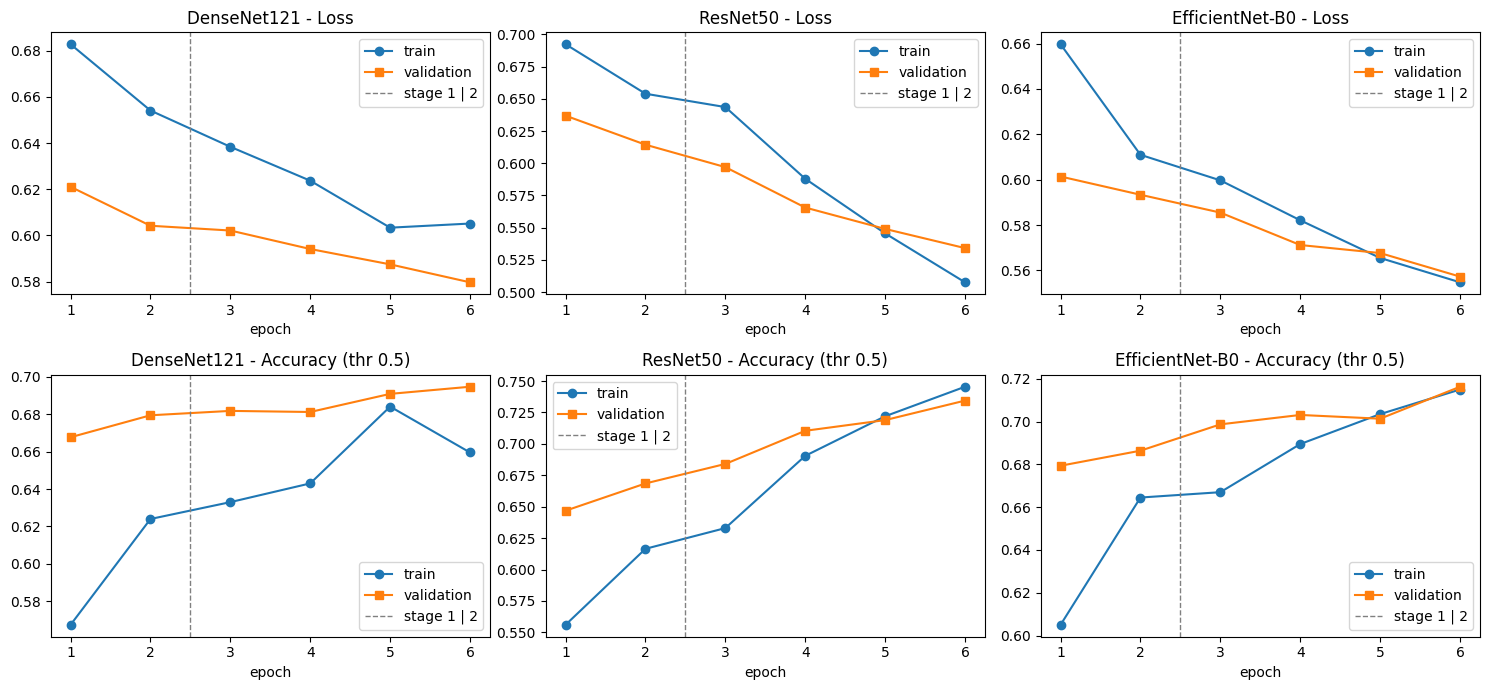

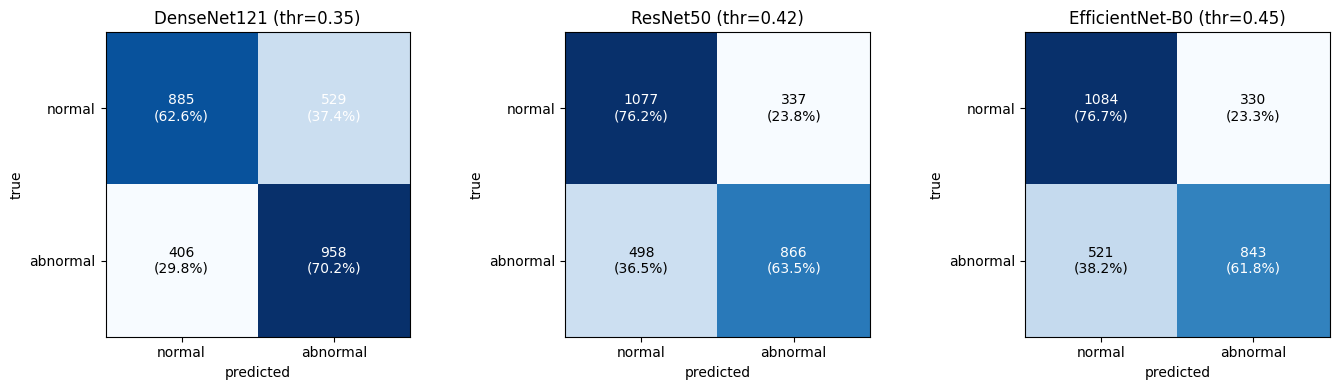

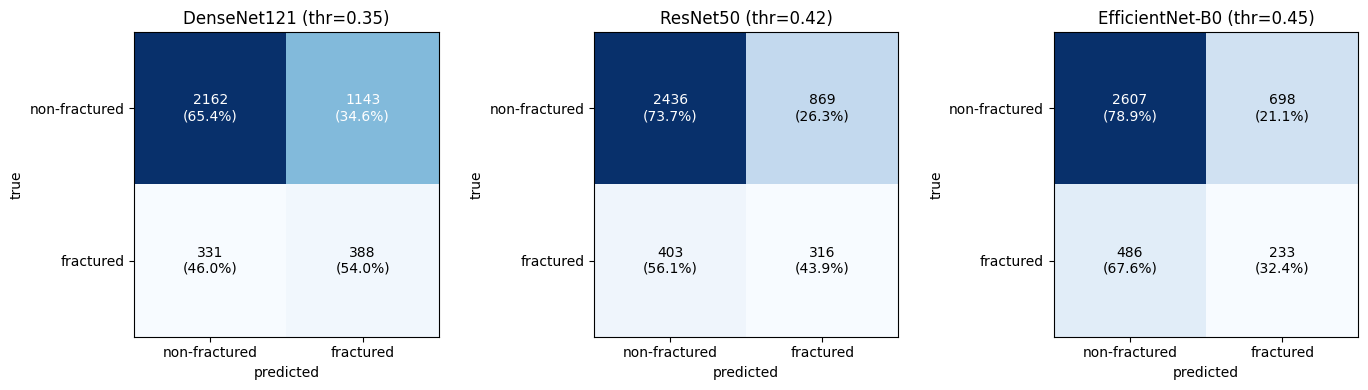

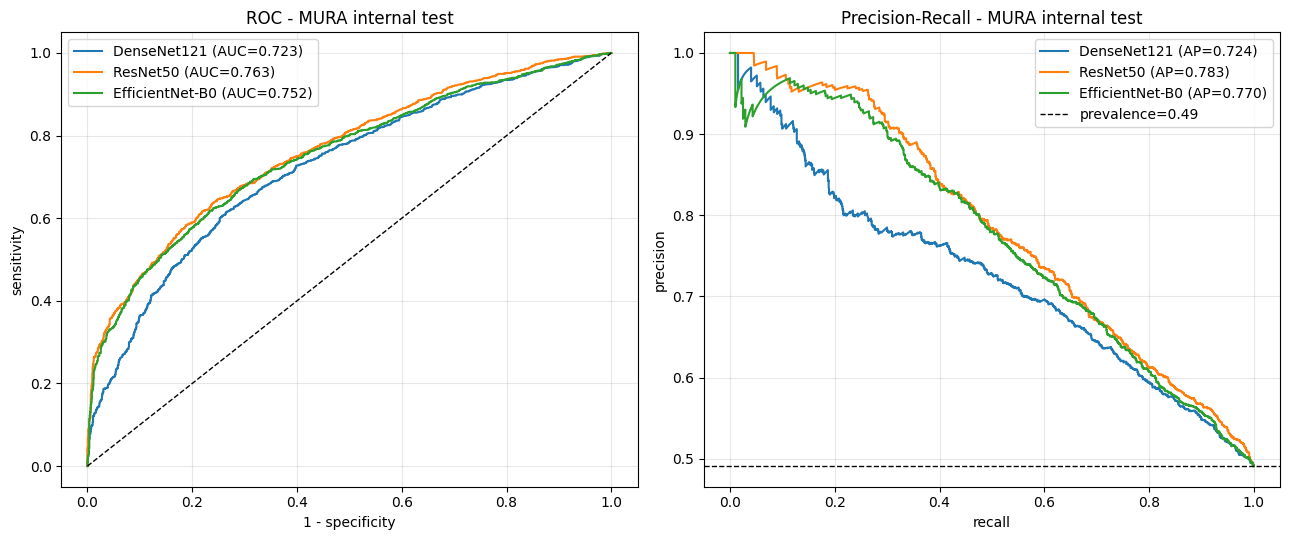

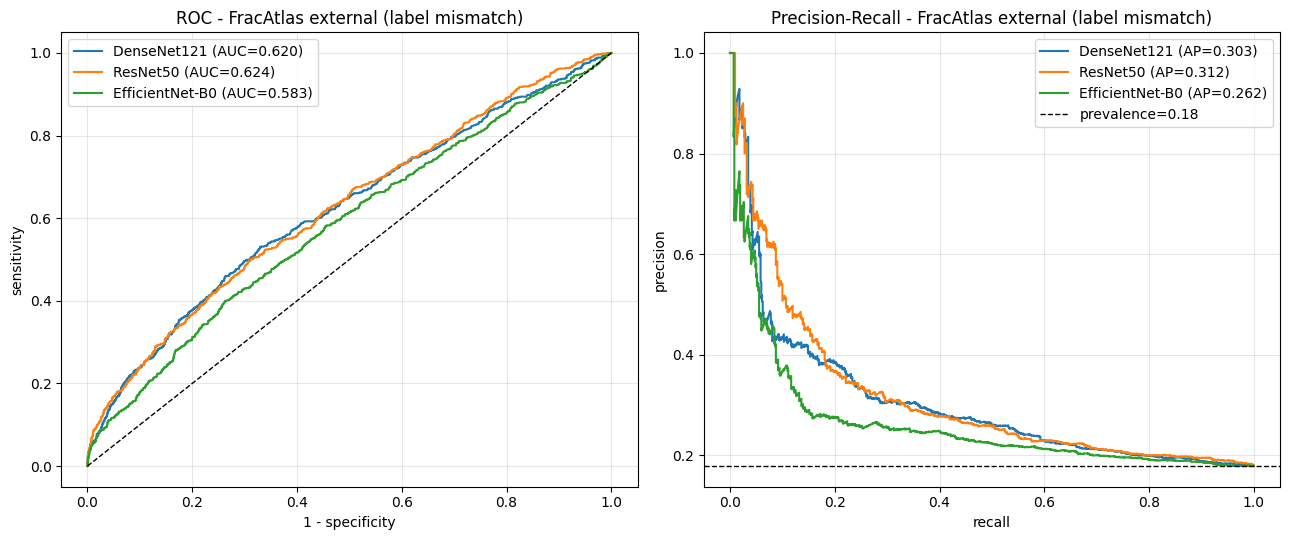

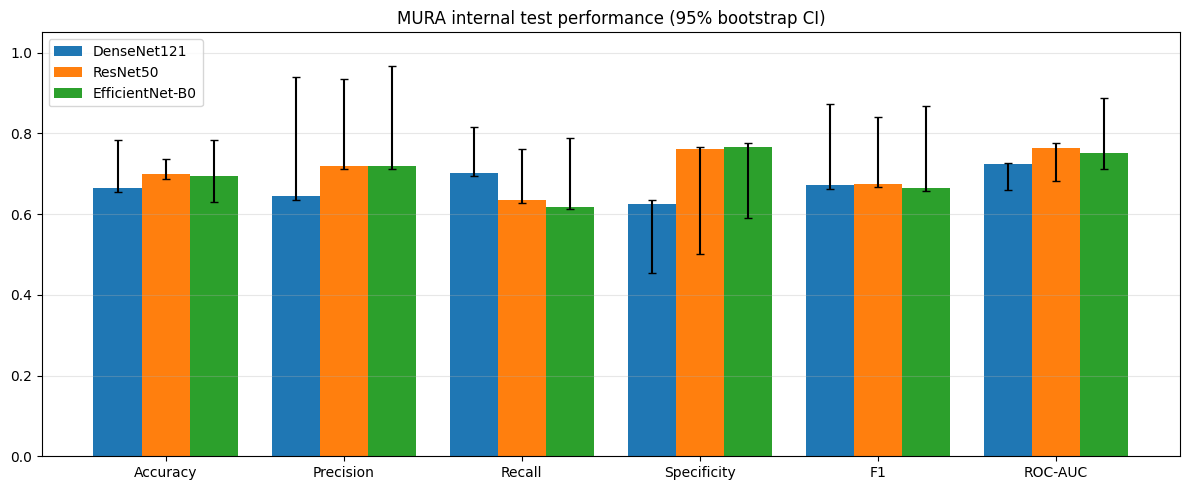

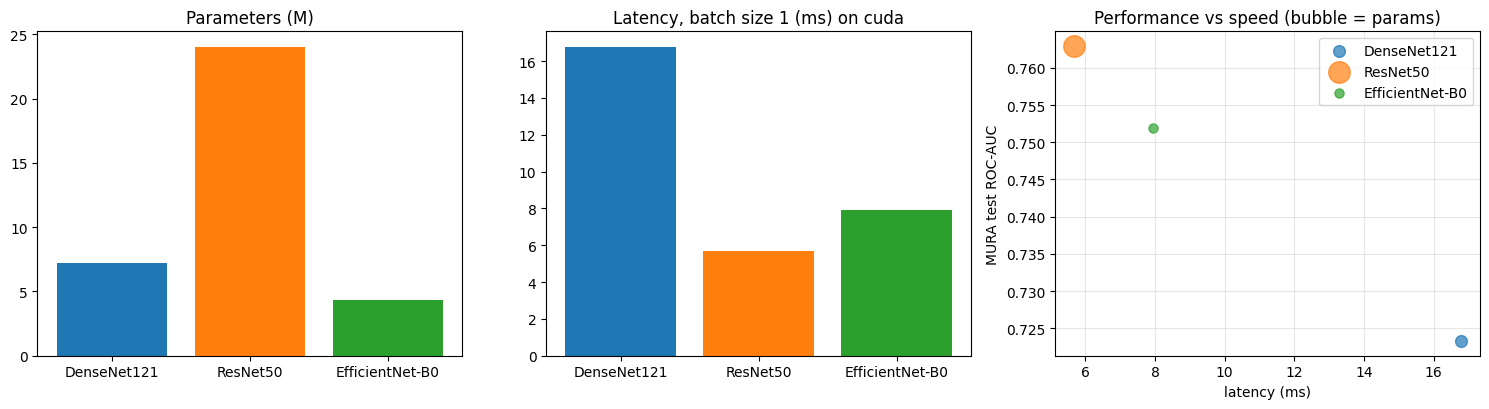

In [21]:
COL = {"densenet121": "tab:blue", "resnet50": "tab:orange", "efficientnet_b0": "tab:green"}
H = {n: pd.read_csv(D_METRICS / f"{n}_history.csv") for n in ARCHS}

# 1+2: training vs validation loss / accuracy
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for c, n in enumerate(ARCHS):
    h = H[n].reset_index(drop=True); x = np.arange(1, len(h) + 1)
    for r, (tr, va, t) in enumerate([("train_loss", "val_loss", "Loss"), ("train_acc", "val_acc", "Accuracy (thr 0.5)")]):
        ax[r, c].plot(x, h[tr], "o-", label="train"); ax[r, c].plot(x, h[va], "s-", label="validation")
        s1 = (h.stage == 1).sum()
        if 0 < s1 < len(h): ax[r, c].axvline(s1 + 0.5, color="gray", ls="--", lw=1, label="stage 1 | 2")
        ax[r, c].set_title(f"{PRETTY[n]} - {t}"); ax[r, c].set_xlabel("epoch"); ax[r, c].legend()
plt.tight_layout(); plt.savefig(D_PLOTS / "training_curves.png", dpi=150); plt.show()

# 3: confusion matrices
def plot_cm(setname, labels, fname):
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    for a, n in zip(ax, ARCHS):
        y, p = PRED[n][setname].label.values, PRED[n][setname].prob.values
        cm = confusion_matrix(y, (p >= THR[n]).astype(int), labels=[0, 1])
        a.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2): a.text(j, i, f"{cm[i, j]}\n({cm[i, j]/cm[i].sum():.1%})", ha="center", va="center",
                                      color="white" if cm[i, j] > cm.max() / 2 else "black")
        a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(labels); a.set_yticklabels(labels)
        a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(f"{PRETTY[n]} (thr={THR[n]:.2f})")
    plt.tight_layout(); plt.savefig(D_CM / fname, dpi=150); plt.show()
plot_cm("test", ["normal", "abnormal"], "confusion_matrices_mura_test.png")
plot_cm("external", ["non-fractured", "fractured"], "confusion_matrices_fracatlas_external.png")

# 4+5: ROC and PR curves
def plot_curves(setname, title, tag):
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
    for n in ARCHS:
        y, p = PRED[n][setname].label.values, PRED[n][setname].prob.values
        fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, color=COL[n], label=f"{PRETTY[n]} (AUC={roc_auc_score(y, p):.3f})")
        pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, color=COL[n], label=f"{PRETTY[n]} (AP={average_precision_score(y, p):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(xlabel="1 - specificity", ylabel="sensitivity", title=f"ROC - {title}")
    ax[1].axhline(y.mean(), color="k", ls="--", lw=1, label=f"prevalence={y.mean():.2f}")
    ax[1].set(xlabel="recall", ylabel="precision", title=f"Precision-Recall - {title}")
    for a in ax: a.legend(loc="best"); a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(D_PLOTS / f"roc_pr_{tag}.png", dpi=150); plt.show()
plot_curves("test", "MURA internal test", "mura_test")
plot_curves("external", "FracAtlas external (label mismatch)", "fracatlas_external")

# 6: comparative performance chart with 95% CI
fig, ax = plt.subplots(figsize=(12, 5)); w = 0.27
for k, n in enumerate(ARCHS):
    v = np.array([MET["test"][n][m] for m in KEYM]); lo = np.array([CI[("test", n)][m][0] for m in KEYM]); hi = np.array([CI[("test", n)][m][1] for m in KEYM])
    ax.bar(np.arange(len(KEYM)) + (k - 1) * w, v, w, yerr=[v - lo, hi - v], capsize=3, color=COL[n], label=PRETTY[n])
ax.set_xticks(range(len(KEYM))); ax.set_xticklabels(["Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC-AUC"])
ax.set_ylim(0, 1.05); ax.set_title("MURA internal test performance (95% bootstrap CI)"); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(D_PLOTS / "performance_comparison_mura.png", dpi=150); plt.show()

# 7: size and speed
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].bar([PRETTY[n] for n in ARCHS], [TRAIN_INFO[n]["total_params"] / 1e6 for n in ARCHS], color=[COL[n] for n in ARCHS]); ax[0].set_title("Parameters (M)")
ax[1].bar([PRETTY[n] for n in ARCHS], [LAT[n][0] for n in ARCHS], color=[COL[n] for n in ARCHS]); ax[1].set_title(f"Latency, batch size 1 (ms) on {device.type}")
for n in ARCHS: ax[2].scatter(LAT[n][0], MET["test"][n]["roc_auc"], s=TRAIN_INFO[n]["total_params"] / 1e5, color=COL[n], alpha=.7, label=PRETTY[n])
ax[2].set(xlabel="latency (ms)", ylabel="MURA test ROC-AUC", title="Performance vs speed (bubble = params)"); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(D_PLOTS / "size_speed_comparison.png", dpi=150); plt.show()

## 12. Explainability (Grad-CAM)
Target = the **abnormal/fracture logit** (evidence for the positive class) for every example, including false positives and false negatives.
Target layers: DenseNet121 `denseblock4`, ResNet50 `layer4`, EfficientNet-B0 `features[-1]`.
A plausible heatmap is **not** evidence of clinical validity.

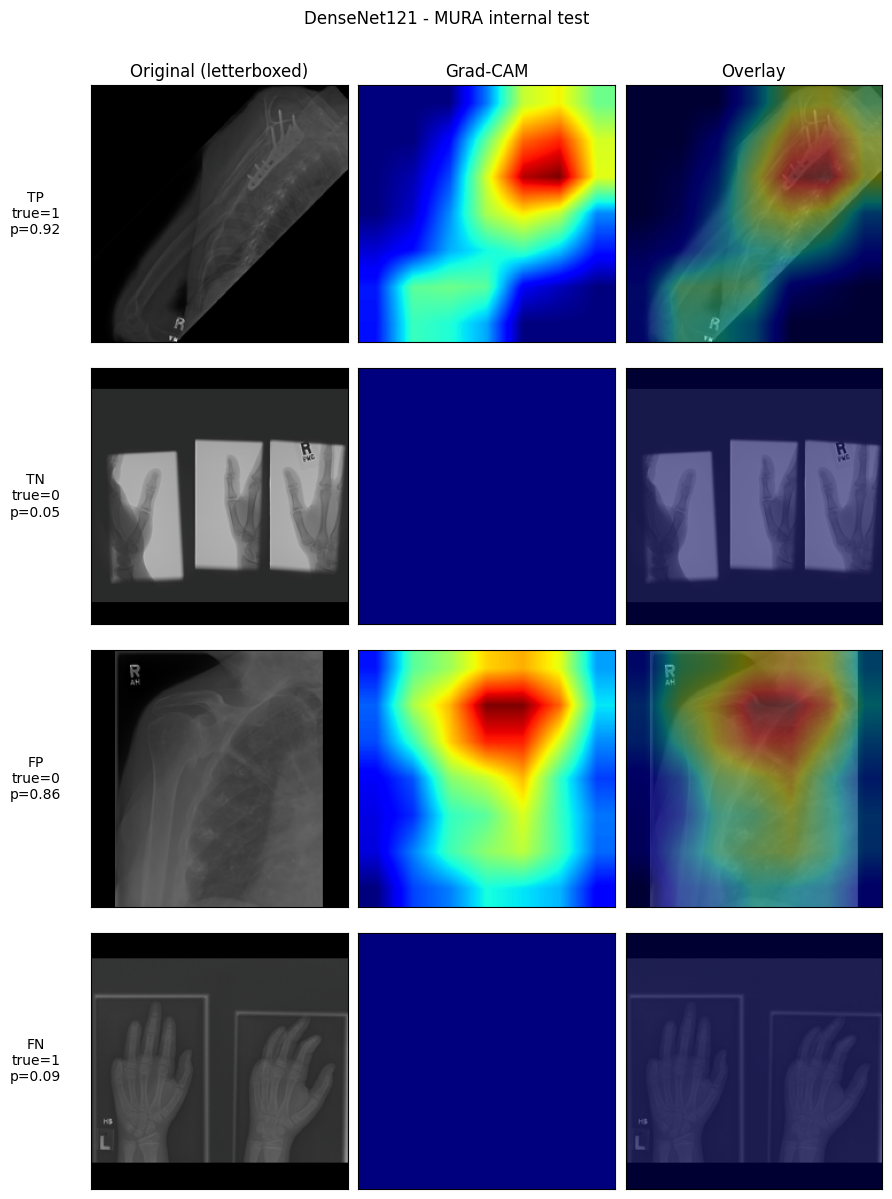

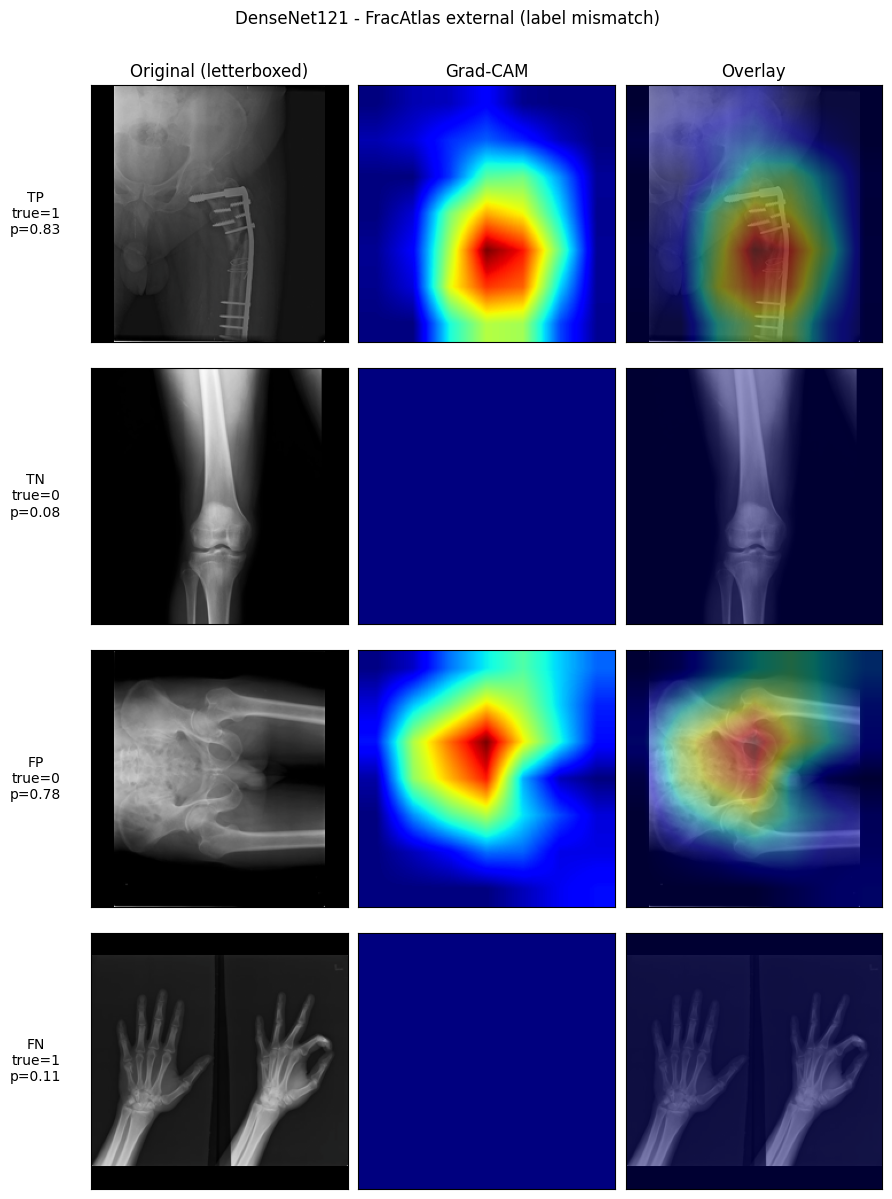

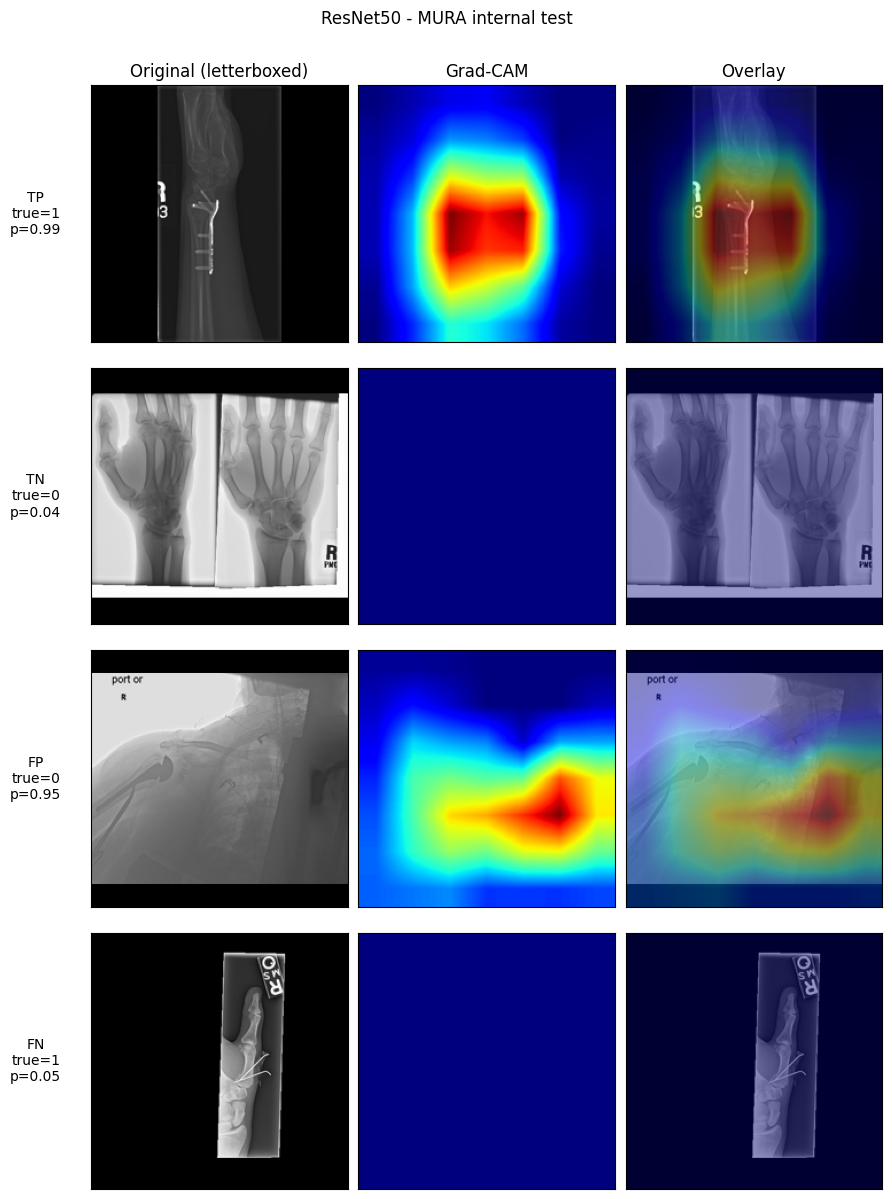

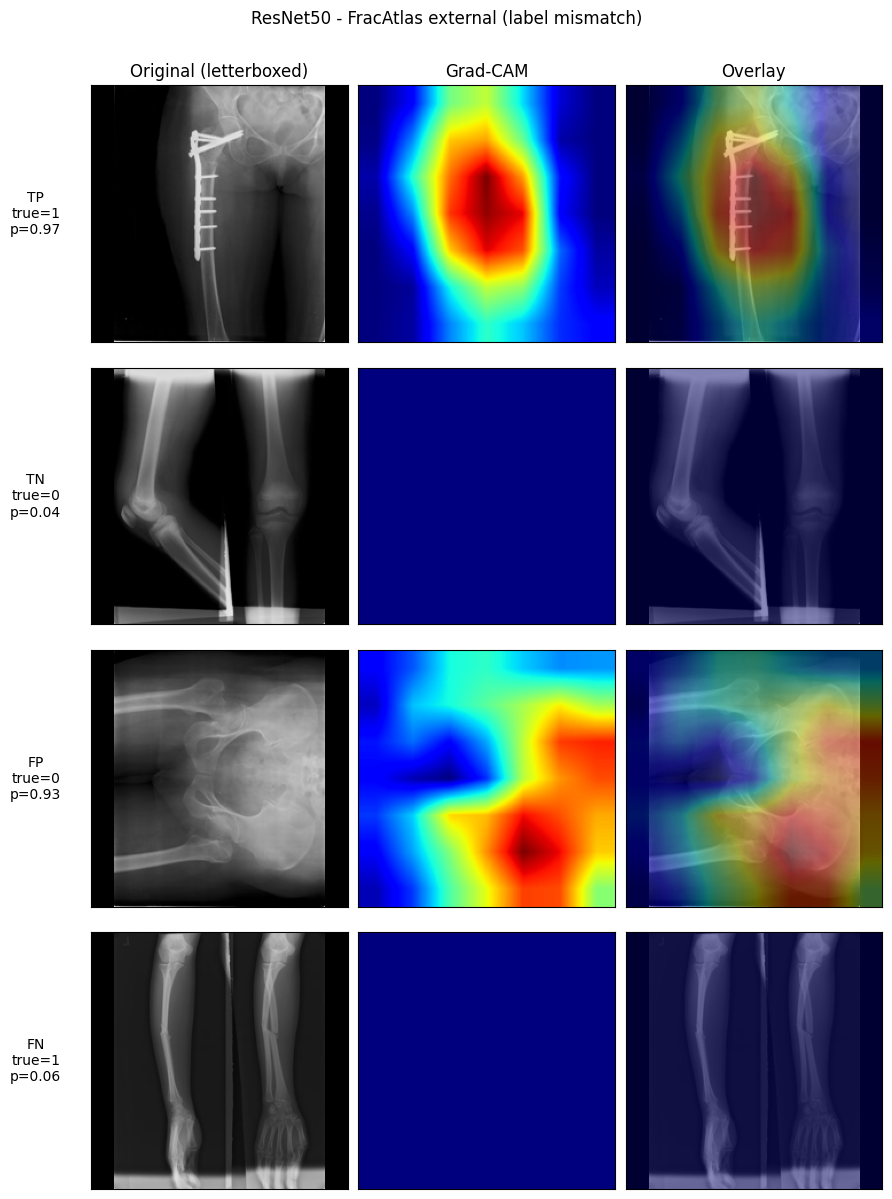

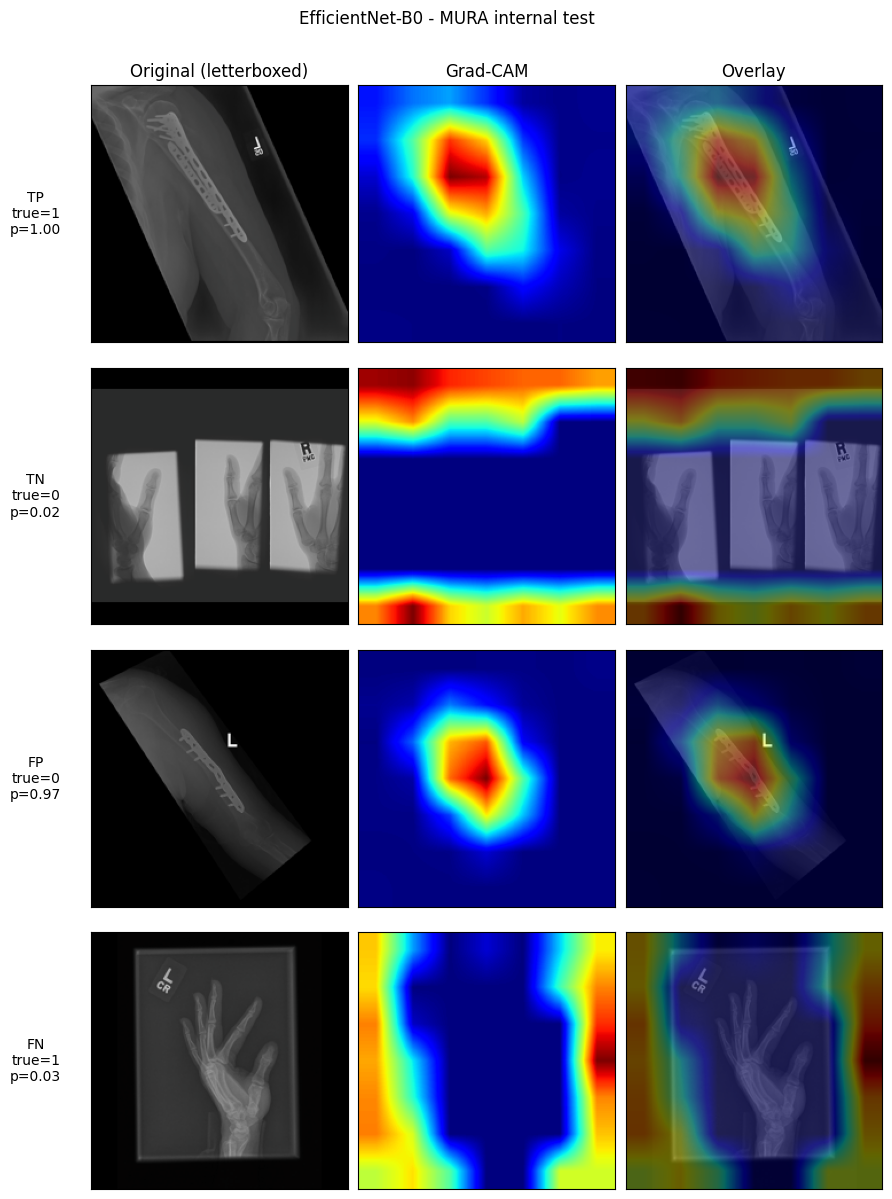

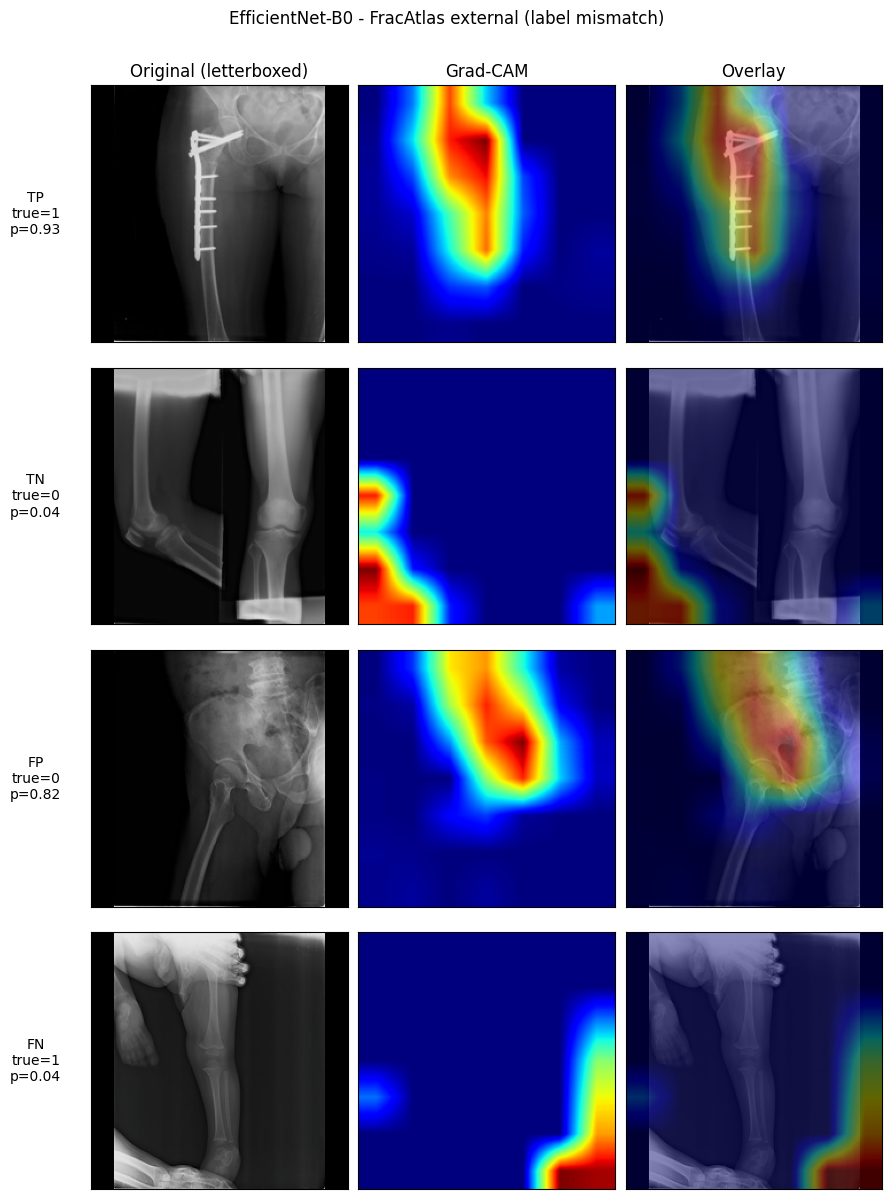

In [23]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._fwd)
    def _fwd(self, mod, inp, out):
        self.acts = out.detach(); out.register_hook(lambda g: setattr(self, "grads", g.detach()))
    def __call__(self, x):
        self.model.zero_grad(set_to_none=True)
        x = x.clone().requires_grad_(True)
        logit = self.model(x).squeeze(1); logit.sum().backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        mn = cam.amax(dim=(1, 2), keepdim=True).clamp_min(1e-8); cam = cam / mn
        return cam.detach().cpu().numpy(), torch.sigmoid(logit).detach().cpu().numpy()

def cam_layer(m, name):
    if name == "densenet121":
        return m.features.denseblock4
    elif name == "resnet50":
        return m.layer4
    elif name == "efficientnet_b0":
        return m.features[-1]
    else:
        raise ValueError(f"Unknown architecture: {name}")

def pick_examples(pred_df, thr, k):
    d = pred_df.copy(); d["pred"] = (d.prob >= thr).astype(int); out = []
    for cat, (yt, yp, asc) in {"TP": (1, 1, False), "TN": (0, 0, True), "FP": (0, 1, False), "FN": (1, 0, True)}.items():
        sub = d[(d.label == yt) & (d.pred == yp)].sort_values("prob", ascending=asc).head(k)
        out += [(cat, r) for _, r in sub.iterrows()]
    return out

def run_gradcam(name, setname, tag):
    model = load_best(name).eval()
    for p in model.parameters(): p.requires_grad = True      # needed so the graph exists
    for mod in model.modules():
        if hasattr(mod, "inplace"): mod.inplace = False
    cam = GradCAM(model, cam_layer(model, name)); tf = get_tf(name, False)
    mean = torch.tensor(WEIGHTS[name].transforms().mean).view(3, 1, 1); std = torch.tensor(WEIGHTS[name].transforms().std).view(3, 1, 1)
    ex = pick_examples(PRED[name][setname], THR[name], CFG["gradcam_per_category"])
    if not ex: return
    fig, axes = plt.subplots(len(ex), 3, figsize=(9, 3 * len(ex)), squeeze=False)
    for r, (cat, row) in enumerate(ex):
        with Image.open(row["path"]) as im: im.load(); x = tf(im)
        heat, prob = cam(x.unsqueeze(0).to(device))
        img = (x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        axes[r, 0].imshow(img); axes[r, 1].imshow(heat[0], cmap="jet", vmin=0, vmax=1)
        axes[r, 2].imshow(img); axes[r, 2].imshow(heat[0], cmap="jet", alpha=0.4, vmin=0, vmax=1)
        axes[r, 0].set_ylabel(f"{cat}\ntrue={int(row["label"])}\np={prob[0]:.2f}", rotation=0, labelpad=40, va="center")
        for c, t in enumerate(["Original (letterboxed)", "Grad-CAM", "Overlay"]):
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
            if r == 0: axes[r, c].set_title(t)
    fig.suptitle(f"{PRETTY[name]} - {tag}", y=1.0); plt.tight_layout()
    plt.savefig(D_CAM / f"gradcam_{name}_{setname}.png", dpi=130, bbox_inches="tight"); plt.show()

for n in ARCHS:
    run_gradcam(n, "test", "MURA internal test")
    run_gradcam(n, "external", "FracAtlas external (label mismatch)")

## 13. Error analysis

In [24]:
attr_cols = ["path", "width", "height", "mean_intensity", "body_part"]
errors_all = []
for n in ARCHS:
    for s, df in [("test", test_df), ("external", ext_df)]:
        d = PRED[n][s].merge(df[attr_cols], on="path", how="left")
        d["pred"] = (d.prob >= THR[n]).astype(int)
        d["error_type"] = np.select([(d.label == 0) & (d.pred == 1), (d.label == 1) & (d.pred == 0)], ["FP", "FN"], "correct")
        d["confidence"] = np.where(d.pred == 1, d.prob, 1 - d.prob)
        d["model"], d["dataset"] = n, "MURA test" if s == "test" else "FracAtlas"
        errors_all.append(d)
        d[d.error_type != "correct"].rename(columns={"label": "true_label", "pred": "predicted_label"}) \
            [["path", "true_label", "predicted_label", "prob", "confidence", "error_type", "width", "height", "mean_intensity", "body_part"]] \
            .to_csv(D_MIS / f"misclassified_{n}_{s}.csv", index=False)
E = pd.concat(errors_all, ignore_index=True)

summ = E[E.error_type != "correct"].groupby(["dataset", "model", "error_type"]).agg(n=("path", "size"), mean_confidence=("confidence", "mean")).reset_index()
tot = E.groupby(["dataset", "model"]).size().rename("n_images").reset_index()
summ = summ.merge(tot, on=["dataset", "model"]); summ["rate_of_all_images"] = summ.n / summ.n_images
summ.to_csv(D_MIS / "error_summary.csv", index=False); display(summ.round(4))

print("Image properties: errors vs correct")
prop = E.groupby(["dataset", "model", "error_type"])[["width", "height", "mean_intensity"]].mean().round(1); prop.to_csv(D_MIS / "error_image_properties.csv"); display(prop)

if E.body_part.notna().any():
    bp = E[E.dataset == "MURA test"].groupby(["model", "body_part"]).apply(lambda g: (g.error_type != "correct").mean()).rename("error_rate").reset_index()
    bp.to_csv(D_MIS / "mura_error_rate_by_body_part.csv", index=False); display(bp.pivot(index="body_part", columns="model", values="error_rate").round(3))

# domain shift: image statistics MURA vs FracAtlas
shift = ok[ok.dataset.isin(["mura", "fracatlas"])].assign(aspect=lambda d: d.width / d.height).groupby("dataset")[["width", "height", "aspect", "mean_intensity"]].agg(["mean", "std"]).round(2)
shift.to_csv(D_MIS / "domain_shift_image_stats.csv"); display(shift)

# images missed/false-alarmed by ALL models
for s, lab in [("MURA test", "MURA test"), ("FracAtlas", "FracAtlas")]:
    sub = E[E.dataset == lab].pivot(index="path", columns="model", values="error_type")
    for et in ["FP", "FN"]:
        k = int((sub == et).all(axis=1).sum()); print(f"{lab}: {et} made by all three models: {k}")
    sub[(sub != "correct").all(axis=1)].to_csv(D_MIS / f"errors_by_all_models_{'test' if s=='MURA test' else 'external'}.csv")

,dataset,model,error_type,n,mean_confidence,n_images,rate_of_all_images
0,FracAtlas,densenet121,FN,331,0.7363,4024,0.0823
1,FracAtlas,densenet121,FP,1143,0.4396,4024,0.2840
2,FracAtlas,efficientnet_b0,FN,486,0.7349,4024,0.1208
3,FracAtlas,efficientnet_b0,FP,698,0.5469,4024,0.1735
4,FracAtlas,resnet50,FN,403,0.7503,4024,0.1001
5,FracAtlas,resnet50,FP,869,0.5517,4024,0.2160
6,MURA test,densenet121,FN,406,0.7479,2778,0.1461
7,MURA test,densenet121,FP,529,0.4723,2778,0.1904
8,MURA test,efficientnet_b0,FN,521,0.7103,2778,0.1875
9,MURA test,efficientnet_b0,FP,330,0.5799,2778,0.1188


Image properties: errors vs correct


width  height  mean_intensity
dataset   model           error_type                               
FracAtlas densenet121     FN          470.4   546.0            47.2
                          FP          558.9   640.5            56.8
                          correct     575.1   647.3            49.6
          efficientnet_b0 FN          609.8   722.8            49.3
                          FP          579.3   628.5            57.0
                          correct     549.4   624.4            50.4
          resnet50        FN          650.1   776.4            49.0
                          FP          581.2   641.8            59.4
                          correct     542.9   615.1            49.3
MURA test densenet121     FN          398.6   491.7            47.7
                          FP          417.5   482.5            52.2
                          correct     396.0   489.9            52.1
          efficientnet_b0 FN          366.0   499.3            47.2
                          FP          433.6   477.4            54.4
                          correct     404.1   487.8            52.1
          resnet50        FN          390.3   490.3            46.9
                          FP          413.5   483.7            54.9
                          correct     400.9   489.2            52.1

model,densenet121,efficientnet_b0,resnet50
body_part,,,
ELBOW,0.000,0.000,0.000
FINGER,0.000,0.000,0.000
SHOULDER,0.332,0.351,0.312
WRIST,0.338,0.304,0.301


width          height         aspect       mean_intensity       
             mean     std    mean     std   mean   std           mean    std
dataset                                                                     
fracatlas  561.88  542.86  637.03  669.78   0.92  0.18          51.42  18.13
mura       399.09   91.99  490.79   47.33   0.84  0.29          52.39  29.57

MURA test: FP made by all three models: 151
MURA test: FN made by all three models: 253
FracAtlas: FP made by all three models: 294
FracAtlas: FN made by all three models: 217


## 14. Auto-generated research summary

In [25]:
def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(f"{v:.3f}" if isinstance(v, float) else str(v) for v in r.values) + " |")
    return "\n".join(lines)

def verdict(s, metric):
    best = max(ARCHS, key=lambda n: MET[s][n][metric]); txt = []
    for n in ARCHS:
        if n == best: continue
        r = pairs_df[(pairs_df.dataset == s) & (pairs_df.metric == metric) &
                     (pairs_df.comparison.isin([f"{PRETTY[best]} - {PRETTY[n]}", f"{PRETTY[n]} - {PRETTY[best]}"]))].iloc[0]
        txt.append(f"{PRETTY[best]} vs {PRETTY[n]}: " + ("95% CI of the difference excludes 0" if r.ci_excludes_zero else "difference not distinguishable from 0 (CI includes 0)"))
    return best, "; ".join(txt)

b_auc, v_auc = verdict("test", "roc_auc"); b_f1, v_f1 = verdict("test", "f1")
fast = min(ARCHS, key=lambda n: LAT[n][0]); small = min(ARCHS, key=lambda n: TRAIN_INFO[n]["total_params"])
quick = min(ARCHS, key=lambda n: TRAIN_INFO[n]["train_seconds"]); b_ext, v_ext = verdict("external", "roc_auc")
banner = "> **SMOKE TEST OUTPUT - tiny subsets, 1 epoch per stage. These numbers are meaningless.**\n\n" if SMOKE_TEST else ""
fp_fn = summ.pivot_table(index=["dataset", "model"], columns="error_type", values="n", fill_value=0).reset_index()

report = f"""# Research results summary
{banner}**Study:** DenseNet121 vs ResNet50 vs EfficientNet-B0 (ImageNet transfer learning) on MURA, with FracAtlas as exploratory external evaluation.
**Positive class:** abnormal (MURA) / fractured (FracAtlas). **Threshold:** chosen on MURA validation ({CFG['threshold_mode']}), then frozen. **Checkpoint selection:** {CFG['selection_metric']}. **Imbalance:** inverse-frequency pos_weight = {POS_WEIGHT:.3f} from training labels. Bootstrap CIs: {CFG['n_boot']} resamples.

## Main comparison
{md_table(comp)}

95% CIs:

{md_table(comp_ci)}

## Research questions
1. **Best on MURA internal test (by ROC-AUC):** {PRETTY[b_auc]} ({MET['test'][b_auc]['roc_auc']:.3f}). {v_auc}. By F1: {PRETTY[b_f1]} ({MET['test'][b_f1]['f1']:.3f}); {v_f1}. A model is only described as better where the paired CI excludes zero.
2. **Sensitivity / specificity / F1 / AUC** are given in the table above (the operating point depends on the validation-selected threshold, so compare sensitivity and specificity together, or use ROC-AUC).
3. **Trade-off:** fewest parameters = {PRETTY[small]} ({TRAIN_INFO[small]['total_params']/1e6:.1f} M); lowest bs=1 latency = {PRETTY[fast]} ({LAT[fast][0]:.1f} ms on {device.type}); shortest training = {PRETTY[quick]} ({TRAIN_INFO[quick]['train_seconds']/60:.1f} min). Weigh these against the AUC differences and their CIs; latency depends on hardware.
4. **FracAtlas generalisation (exploratory):** best external ROC-AUC = {PRETTY[b_ext]} ({MET['external'][b_ext]['roc_auc']:.3f}). {v_ext}.
5. **Errors:** FP/FN counts per model and dataset:

{md_table(fp_fn)}

Grad-CAM figures: `{D_CAM.name}/`. Per-image errors: `{D_MIS.name}/`.

## Label mismatch and domain shift
MURA's *abnormal* label covers fractures but also hardware, degenerative change, lesions and other findings; FracAtlas separates *fractured* from *non-fractured*. Using P(abnormal) as a fracture score on FracAtlas is therefore an exploratory cross-dataset test with imperfectly aligned labels. It is **not** a clinically validated fracture-diagnosis result. Differences in scanner, projection, body-region mix, collection site and image resolution add domain shift (see `domain_shift_image_stats.csv`).

## Limitations
* One training run (single seed) per model; run-to-run variance is not captured by the bootstrap CIs, which reflect test-set sampling only.
* No hyper-parameter search; learning rates were fixed a priori per architecture (documented in `experiment_config.json`).
* MURA image-level labels come from study-level labels; patient-level clustering is only possible if patient ids were recoverable in the audit.
* FracAtlas has no recoverable patient id in the prepared data, so its CIs are image-level.
* The decision threshold is tuned on MURA validation and may not transfer to FracAtlas, where the prevalence and label definition differ.
* Latency was measured on the hardware used here with synthetic input and excludes data loading.
* Grad-CAM shows where the network responds, not clinical correctness.

## Future work
Multiple seeds and ensembling, patient-/study-level aggregation as in MURA's official protocol, body-part-specific models, calibration analysis, external threshold/calibration adaptation using a *separate* held-out FracAtlas split, evaluation on additional external sets, and review of errors by a radiologist.
"""
(RESULTS / "RESEARCH_SUMMARY.md").write_text(report, encoding="utf-8")
display(Markdown(report))
print("Saved:", RESULTS / "RESEARCH_SUMMARY.md")

# Research results summary
**Study:** DenseNet121 vs ResNet50 vs EfficientNet-B0 (ImageNet transfer learning) on MURA, with FracAtlas as exploratory external evaluation.
**Positive class:** abnormal (MURA) / fractured (FracAtlas). **Threshold:** chosen on MURA validation (val_youden), then frozen. **Checkpoint selection:** val_auc. **Imbalance:** inverse-frequency pos_weight = 1.000 from training labels. Bootstrap CIs: 100 resamples.

## Main comparison
| Model | MURA accuracy | MURA precision | MURA recall | MURA specificity | MURA F1 | MURA ROC-AUC | FracAtlas ROC-AUC | FracAtlas F1 | Params | Training time (min) | Latency bs=1 (ms) | Latency bs=batch (ms/img) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| DenseNet121 | 0.663 | 0.644 | 0.702 | 0.626 | 0.672 | 0.723 | 0.620 | 0.345 | 7216513 | 3.463 | 16.775 | 3.013 |
| ResNet50 | 0.699 | 0.720 | 0.635 | 0.762 | 0.675 | 0.763 | 0.624 | 0.332 | 24032833 | 3.360 | 5.681 | 2.957 |
| EfficientNet-B0 | 0.694 | 0.719 | 0.618 | 0.767 | 0.665 | 0.752 | 0.583 | 0.282 | 4335741 | 3.327 | 7.934 | 1.358 |

95% CIs:

| Model | MURA accuracy | MURA precision | MURA recall | MURA specificity | MURA f1 | MURA roc_auc | FracAtlas roc_auc | FracAtlas f1 | FracAtlas recall | FracAtlas specificity |
|---|---|---|---|---|---|---|---|---|---|---|
| DenseNet121 | 0.663 [0.654, 0.784] | 0.644 [0.635, 0.939] | 0.702 [0.693, 0.815] | 0.626 [0.455, 0.635] | 0.672 [0.663, 0.872] | 0.723 [0.658, 0.726] | 0.620 [0.592, 0.644] | 0.345 [0.319, 0.372] | 0.540 [0.503, 0.571] | 0.654 [0.639, 0.670] |
| ResNet50 | 0.699 [0.686, 0.737] | 0.720 [0.711, 0.935] | 0.635 [0.627, 0.762] | 0.762 [0.500, 0.767] | 0.675 [0.666, 0.839] | 0.763 [0.682, 0.775] | 0.624 [0.601, 0.649] | 0.332 [0.308, 0.360] | 0.439 [0.409, 0.477] | 0.737 [0.720, 0.751] |
| EfficientNet-B0 | 0.694 [0.630, 0.784] | 0.719 [0.711, 0.967] | 0.618 [0.611, 0.788] | 0.767 [0.591, 0.775] | 0.665 [0.658, 0.869] | 0.752 [0.711, 0.887] | 0.583 [0.565, 0.612] | 0.282 [0.256, 0.313] | 0.324 [0.298, 0.358] | 0.789 [0.776, 0.803] |

## Research questions
1. **Best on MURA internal test (by ROC-AUC):** ResNet50 (0.763). ResNet50 vs DenseNet121: difference not distinguishable from 0 (CI includes 0); ResNet50 vs EfficientNet-B0: difference not distinguishable from 0 (CI includes 0). By F1: ResNet50 (0.675); ResNet50 vs DenseNet121: difference not distinguishable from 0 (CI includes 0); ResNet50 vs EfficientNet-B0: difference not distinguishable from 0 (CI includes 0). A model is only described as better where the paired CI excludes zero.
2. **Sensitivity / specificity / F1 / AUC** are given in the table above (the operating point depends on the validation-selected threshold, so compare sensitivity and specificity together, or use ROC-AUC).
3. **Trade-off:** fewest parameters = EfficientNet-B0 (4.3 M); lowest bs=1 latency = ResNet50 (5.7 ms on cuda); shortest training = EfficientNet-B0 (3.3 min). Weigh these against the AUC differences and their CIs; latency depends on hardware.
4. **FracAtlas generalisation (exploratory):** best external ROC-AUC = ResNet50 (0.624). ResNet50 vs DenseNet121: difference not distinguishable from 0 (CI includes 0); ResNet50 vs EfficientNet-B0: 95% CI of the difference excludes 0.
5. **Errors:** FP/FN counts per model and dataset:

| dataset | model | FN | FP |
|---|---|---|---|
| FracAtlas | densenet121 | 331.000 | 1143.000 |
| FracAtlas | efficientnet_b0 | 486.000 | 698.000 |
| FracAtlas | resnet50 | 403.000 | 869.000 |
| MURA test | densenet121 | 406.000 | 529.000 |
| MURA test | efficientnet_b0 | 521.000 | 330.000 |
| MURA test | resnet50 | 498.000 | 337.000 |

Grad-CAM figures: `gradcam/`. Per-image errors: `misclassified/`.

## Label mismatch and domain shift
MURA's *abnormal* label covers fractures but also hardware, degenerative change, lesions and other findings; FracAtlas separates *fractured* from *non-fractured*. Using P(abnormal) as a fracture score on FracAtlas is therefore an exploratory cross-dataset test with imperfectly aligned labels. It is **not** a clinically validated fracture-diagnosis result. Differences in scanner, projection, body-region mix, collection site and image resolution add domain shift (see `domain_shift_image_stats.csv`).

## Limitations
* One training run (single seed) per model; run-to-run variance is not captured by the bootstrap CIs, which reflect test-set sampling only.
* No hyper-parameter search; learning rates were fixed a priori per architecture (documented in `experiment_config.json`).
* MURA image-level labels come from study-level labels; patient-level clustering is only possible if patient ids were recoverable in the audit.
* FracAtlas has no recoverable patient id in the prepared data, so its CIs are image-level.
* The decision threshold is tuned on MURA validation and may not transfer to FracAtlas, where the prevalence and label definition differ.
* Latency was measured on the hardware used here with synthetic input and excludes data loading.
* Grad-CAM shows where the network responds, not clinical correctness.

## Future work
Multiple seeds and ensembling, patient-/study-level aggregation as in MURA's official protocol, body-part-specific models, calibration analysis, external threshold/calibration adaptation using a *separate* held-out FracAtlas split, evaluation on additional external sets, and review of errors by a radiologist.


Saved: /content/results/RESEARCH_SUMMARY.md


In [26]:
import shutil
shutil.make_archive('/content/results', 'zip', '/content/results')
print("Successfully created /content/results.zip")

Successfully created /content/results.zip
